# Linear Models Lab – Nhóm 9 · Machine Learning
**Chủ đề:** Regression Algorithms – 1. Linear Models (Linear Regression, Ridge, Lasso, ElasticNet)
**Dữ liệu:** Medical Cost Personal (`insurance.csv`, Kaggle) · **Biến mục tiêu:** `charges` (USD)

Một notebook duy nhất. Tiền xử lý chạy **1 lần**, cả 4 mô hình dùng chung. Chọn *Run all* là ra đủ bảng và hình. Chạy được từ thư mục gốc dự án hoặc từ `notebooks/`.

| Phần | Nội dung |
| :---: | :--- |
| 1 | Tiền xử lý dữ liệu chuẩn (drop duplicates, `OneHotEncoder(drop="first")`, `StandardScaler`) |
| 2 | Huấn luyện đồng thời 4 mô hình, **Bảng 1** (MSE, RMSE, MAE, R², Zero_Weights), **Bảng 2** (trọng số w), đối chiếu bảng mẫu |
| 2.5 | Cross-Validation 5-fold trên Train (Pipeline, không dùng Test) |
| 3 | Trực quan so sánh tổng hợp: 5A, 5B, 5C, 5D |
| 4.1 | Linear Regression (OLS): hồi quy đơn biến, phương trình chuẩn, phân tích phần dư |
| 4.2 | Ridge (L2): hệ số co lại theo alpha (Coefficient Path), VIF |
| 4.3 | **Lasso (L1)**: lý thuyết, Coordinate Descent tự cài, KKT, Lasso path, chọn alpha, Hình 1–4 |
| 4.4 | ElasticNet (L1+L2): công thức sklearn, tác động của l1_ratio, tính ổn định nhóm biến |
| 5 | Tổng kết |

---
# Phần 1. Tiền xử lý dữ liệu chuẩn (chạy duy nhất 1 lần)

**mọi mô hình dùng chung `X_tr`, `X_te`, `y_train`, `y_test` tạo ở ô 1.4**. Không ô nào khác được đọc lại file hay chia lại dữ liệu. Riêng Cross-Validation (từ mục 2.5) dùng `Pipeline` để mã hóa/chuẩn hóa được fit lại trong từng fold.

### 1.1 Import thư viện và siêu tham số chuẩn
Siêu tham số là giá trị đã chốt trong slide và thỏa thuận nhóm:

| Mô hình | Siêu tham số |
| :--- | :--- |
| Linear Regression | không có |
| Ridge | $\alpha = 10$ |
| Lasso | $\alpha = 100$ |
| ElasticNet | $\alpha = 100,\ \text{l1\_ratio} = 0.9998$ |

In [1]:
from pathlib import Path
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, lasso_path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ---- Đường dẫn: chạy được từ thư mục gốc dự án hoặc từ notebooks/ ----
ROOT = Path.cwd()
if not (ROOT / "data" / "insurance.csv").exists() and (ROOT.parent / "data" / "insurance.csv").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "insurance.csv"
PLOTS_DIR = ROOT / "docs" / "images"     # 14 hình PNG
OUT_DIR = ROOT / "outputs"               # các file CSV kết quả
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ---- Siêu tham số chuẩn của nhóm ----
ALPHA_RIDGE = 10.0        # Ridge
ALPHA = 100.0             # Lasso (giữ tên ALPHA vì toàn bộ phần 4.3 dùng tên này)
ALPHA_EN = 100.0          # ElasticNet
L1_RATIO_EN = 0.9998      # ElasticNet
MAX_ITER = 20000          # Lasso và ElasticNet
TEST_SIZE = 0.2           # 80% train / 20% test
SEED = 42                 # random_state cố định để ai chạy cũng ra cùng số
CV_FOLDS = 5              # số fold của Cross-Validation (chỉ trên Train)
ZERO_TOL = 1e-4           # |w| nhỏ hơn ngưỡng này được tính là bằng 0

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"axes.grid": True, "grid.linestyle": "--", "grid.alpha": 0.35})

MODEL_ORDER = ["OLS", "Ridge", "Lasso", "ElasticNet"]
MODEL_COLORS = {"OLS": "#3498db", "Ridge": "#8e44ad", "Lasso": "#e67e22", "ElasticNet": "#27ae60"}
MODEL_LABELS = {
    "OLS": "Linear Regression (OLS)",
    "Ridge": "Ridge (L2, α=10)",
    "Lasso": "Lasso (L1, α=100)",
    "ElasticNet": "ElasticNet (L1+L2, α=100, l1_ratio=0.9998)",
}
COLORS = {"age": "#1f77b4", "bmi": "#ff7f0e", "children": "#2ca02c", "sex_male": "#d62728",
          "smoker_yes": "#9467bd", "region_northwest": "#8c564b",
          "region_southeast": "#e377c2", "region_southwest": "#17becf"}

### 1.2 Nạp dữ liệu
Thứ tự thử: (1) file `data/insurance.csv` của dự án, (2) tải từ nguồn công khai của bộ dữ liệu, (3) nếu đang ở Colab mà vẫn lỗi thì hiện nút upload.

In [2]:
CSV_URL = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"

def load_data():
    if DATA_PATH.exists():
        print("Đọc file local:", DATA_PATH.relative_to(ROOT))
        return pd.read_csv(DATA_PATH)
    try:
        print("Không thấy file local, tải từ nguồn công khai...")
        return pd.read_csv(CSV_URL)
    except Exception as e:
        print("Tải thất bại:", e)
    try:
        from google.colab import files        # chỉ có trên Colab
        print("Hãy chọn file insurance.csv từ máy của bạn:")
        files.upload()
        return pd.read_csv("insurance.csv")
    except ImportError:
        raise FileNotFoundError("Đặt insurance.csv vào thư mục data/ rồi chạy lại.")

df_raw = load_data()
print(f"Kích thước gốc: {df_raw.shape} | Giá trị thiếu: {df_raw.isnull().sum().sum()} | Dòng trùng: {df_raw.duplicated().sum()}")
df_raw.head()

Đọc file local: data/insurance.csv
Kích thước gốc: (1338, 7) | Giá trị thiếu: 0 | Dòng trùng: 1


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.90,0,yes,southwest,"16,884.92"
1,18,male,33.77,1,no,southeast,"1,725.55"
2,28,male,33.00,3,no,southeast,"4,449.46"
3,33,male,22.70,0,no,northwest,"21,984.47"
4,32,male,28.88,0,no,northwest,"3,866.86"


### 1.3 Làm sạch và chia train/test (1 lần duy nhất)
- Bỏ 1 dòng trùng hoàn toàn: 1,338 → **1,337** dòng.
- Chia 80/20: **1,069 train / 268 test**.
- Biến mục tiêu `charges` là chi phí bảo hiểm y tế (USD).

In [3]:
df = df_raw.drop_duplicates().reset_index(drop=True)
X = df.drop(columns="charges")
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED)
print("Sau làm sạch:", df.shape, "| Train:", X_train.shape, "| Test:", X_test.shape)
df.describe().T[["min", "mean", "std", "max"]]

Sau làm sạch: (1337, 7) | Train: (1069, 6) | Test: (268, 6)


,min,mean,std,max
age,18.00,39.22,14.04,64.00
bmi,15.96,30.66,6.10,53.13
children,0.00,1.10,1.21,5.00
charges,"1,121.87","13,279.12","12,110.36","63,770.43"


### 1.4 Mã hóa và chuẩn hóa (dùng chung cho cả 4 mô hình)
| Bước | Làm gì | Vì sao |
| :--- | :--- | :--- |
| One-hot với `drop="first"` | `sex`, `smoker`, `region` → các cột 0/1, bỏ 1 cột mỗi nhóm | Nếu giữ cả `smoker_no` và `smoker_yes` thì tổng = 1 (đa cộng tuyến hoàn hảo), Lasso từng xóa nhầm `smoker_yes` |
| `StandardScaler` | Mỗi cột có mean 0, std 1 | Phạt L1 cộng thẳng trên w, nên các biến phải cùng thang đo mới bị phạt công bằng |
| Fit trên train, chỉ transform test | Không dùng thông tin test | Tránh rò rỉ dữ liệu (data leakage) |

In [4]:
preprocessor = Pipeline([
    ("encode", ColumnTransformer([
        ("num", "passthrough", ["age", "bmi", "children"]),
        ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"),
         ["sex", "smoker", "region"]),
    ])),
    ("scale", StandardScaler()),
])

X_tr = preprocessor.fit_transform(X_train)      # fit trên TRAIN
X_te = preprocessor.transform(X_test)           # test chỉ transform
feat = [f.replace("num__", "").replace("cat__", "")
        for f in preprocessor.named_steps["encode"].get_feature_names_out()]
y_tr = y_train.to_numpy()
n = len(y_tr)

print("Các đặc trưng:", feat)
print("Kiểm tra chuẩn hóa -> mean ≈ 0, std = 1 trên train:")
pd.DataFrame(X_tr, columns=feat).agg(["mean", "std"]).round(3)

Các đặc trưng: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']
Kiểm tra chuẩn hóa -> mean ≈ 0, std = 1 trên train:


,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
mean,0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


**Kiểm tra tự động.** Ô dưới dừng notebook nếu tiền xử lý lệch chuẩn (sai số dòng, sai số cột, thiếu `drop="first"`). Ma trận hạng đủ 8 nghĩa là không còn đa cộng tuyến hoàn hảo giữa các cột biến giả.

In [5]:
assert df_raw.shape == (1338, 7), "File gốc phải có 1,338 dòng"
assert df.shape == (1337, 7), "Sau drop_duplicates phải còn 1,337 dòng"
assert X_train.shape[0] == 1069 and X_test.shape[0] == 268, "Chia 80/20 phải ra 1,069 / 268"
assert X_tr.shape == (1069, 8) and X_te.shape == (268, 8), "Phải có đúng 8 đặc trưng (drop='first')"
assert np.linalg.matrix_rank(X_tr) == 8, "Ma trận thiết kế phải đủ hạng (không dính bẫy biến giả)"

print("OK: 1,337 dòng | train 1,069 / test 268 | 8 đặc trưng | hạng ma trận =", np.linalg.matrix_rank(X_tr))
print("Đặc trưng:", feat)

OK: 1,337 dòng | train 1,069 / test 268 | 8 đặc trưng | hạng ma trận = 8
Đặc trưng: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


---
# Phần 2. Huấn luyện đồng thời 4 mô hình và bảng so sánh

Cả 4 mô hình **fit trên `X_tr` (train)** rồi **chấm trên `X_te` (test)**. Không mô hình nào được fit trên toàn bộ dữ liệu.

**Hàm mục tiêu thật sự của sklearn** (quan trọng khi đổi sang công thức trong slide):

| Mô hình | Hàm mục tiêu trong sklearn |
| :--- | :--- |
| OLS | $\lVert y-Xw\rVert_2^2$ |
| Ridge | $\lVert y-Xw\rVert_2^2+\alpha\lVert w\rVert_2^2$ |
| Lasso | $\frac{1}{2n}\lVert y-Xw\rVert_2^2+\alpha\lVert w\rVert_1$ |
| ElasticNet | $\frac{1}{2n}\lVert y-Xw\rVert_2^2+\alpha\rho\lVert w\rVert_1+\frac{\alpha(1-\rho)}{2}\lVert w\rVert_2^2$, với $\rho=$ `l1_ratio` |

Ridge **không** chia $2n$, Lasso và ElasticNet **có** chia. Vì vậy $\alpha=10$ của Ridge và $\alpha=100$ của Lasso không so sánh trực tiếp được về độ mạnh phạt.

In [6]:
models = {
    "OLS": LinearRegression(),
    "Ridge": Ridge(alpha=ALPHA_RIDGE),
    "Lasso": Lasso(alpha=ALPHA, max_iter=MAX_ITER),
    "ElasticNet": ElasticNet(alpha=ALPHA_EN, l1_ratio=L1_RATIO_EN, max_iter=MAX_ITER),
}
for name in MODEL_ORDER:
    models[name].fit(X_tr, y_train)            # CHỈ fit trên tập train

ols, ridge, las, enet = (models[k] for k in MODEL_ORDER)
y_pred = {k: models[k].predict(X_te) for k in MODEL_ORDER}      # dự đoán trên tập test
y_pred_train = {k: models[k].predict(X_tr) for k in MODEL_ORDER}

def zero_names(model):
    # tên các biến có trọng số bằng 0
    return [f for f, c in zip(feat, model.coef_) if abs(c) < ZERO_TOL]

rows = []
for k in MODEL_ORDER:
    mse = mean_squared_error(y_test, y_pred[k])
    rows.append({"Model": k, "MSE": mse, "RMSE": np.sqrt(mse),
                 "MAE": mean_absolute_error(y_test, y_pred[k]), "R2": r2_score(y_test, y_pred[k]),
                 "Zero_Weights": len(zero_names(models[k]))})
results_num = pd.DataFrame(rows).set_index("Model")             # bảng số, dùng cho code phía sau

W = pd.DataFrame({k: models[k].coef_ for k in MODEL_ORDER}, index=feat)    # bảng trọng số w
W.index.name = "Feature"
W = W.mask(W.abs() < ZERO_TOL, 0.0)                              # tránh hiển thị -0.00
print("Đã huấn luyện xong 4 mô hình. Intercept (= mean y_train):",
      {k: round(float(models[k].intercept_), 2) for k in MODEL_ORDER})

Đã huấn luyện xong 4 mô hình. Intercept (= mean y_train): {'OLS': 13030.2, 'Ridge': 13030.2, 'Lasso': 13030.2, 'ElasticNet': 13030.2}


### 2.1 BẢNG 1: kết quả đánh giá trên tập Test (`model_results.csv`)
`Zero_Weights` là số trọng số bị triệt tiêu về đúng 0 (bằng chứng chọn lọc đặc trưng).

In [7]:
table1 = pd.DataFrame({
    "Model": [MODEL_LABELS[k] for k in MODEL_ORDER],
    "MSE": [f"{results_num.loc[k, 'MSE']:,.2f}" for k in MODEL_ORDER],
    "RMSE ($)": [f"{results_num.loc[k, 'RMSE']:,.2f}" for k in MODEL_ORDER],
    "MAE ($)": [f"{results_num.loc[k, 'MAE']:,.2f}" for k in MODEL_ORDER],
    "R² Score": [f"{results_num.loc[k, 'R2']:.4f}" for k in MODEL_ORDER],
    "Zero_Weights": [int(results_num.loc[k, "Zero_Weights"]) for k in MODEL_ORDER],
    "Biến bị triệt tiêu (=0)": [", ".join(zero_names(models[k])) or "-" for k in MODEL_ORDER],
}).set_index("Model")
display(table1)
results_num.round(6).to_csv(OUT_DIR / "model_results.csv")

,MSE,RMSE ($),MAE ($),R² Score,Zero_Weights,Biến bị triệt tiêu (=0)
Model,,,,,,
Linear Regression (OLS),"35,478,020.68","5,956.34","4,177.05",0.8069,0,-
"Ridge (L2, α=10)","35,828,958.09","5,985.73","4,202.58",0.8050,0,-
"Lasso (L1, α=100)","36,319,178.48","6,026.54","4,202.30",0.8024,2,"sex_male, region_northwest"
"ElasticNet (L1+L2, α=100, l1_ratio=0.9998)","37,130,891.34","6,093.51","4,261.29",0.7979,2,"sex_male, region_northwest"


### 2.2 BẢNG 2: trọng số $w$ sau `StandardScaler` (`model_weights.csv`)
Trọng số đo trên thang đã chuẩn hóa nên so sánh được giữa các biến: đổi 1 độ lệch chuẩn của biến thì `charges` đổi bấy nhiêu USD.

In [8]:
NOTES = {
    "smoker_yes": "Tác động mạnh nhất -> Giữ lại",
    "age": "Tác động lớn thứ 2 -> Giữ lại",
    "bmi": "Tác động lớn thứ 3 -> Giữ lại",
    "children": "Co rút nhẹ -> Giữ lại",
    "region_southeast": "Co rút mạnh về gần 0",
    "region_southwest": "Co rút mạnh về gần 0",
    "region_northwest": "Lasso & ElasticNet loại bỏ (w=0)",
    "sex_male": "Lasso & ElasticNet loại bỏ (w=0)",
}
FEATURE_ORDER = ["smoker_yes", "age", "bmi", "children", "region_southeast",
                 "region_southwest", "region_northwest", "sex_male"]

table2 = pd.DataFrame({
    "OLS": [f"{W.loc[f, 'OLS']:+,.2f}" for f in FEATURE_ORDER],
    "Ridge (L2)": [f"{W.loc[f, 'Ridge']:+,.2f}" for f in FEATURE_ORDER],
    "Lasso (L1)": [f"{W.loc[f, 'Lasso']:+,.2f}" if W.loc[f, "Lasso"] != 0 else "0.00" for f in FEATURE_ORDER],
    "ElasticNet": [f"{W.loc[f, 'ElasticNet']:+,.2f}" if W.loc[f, "ElasticNet"] != 0 else "0.00" for f in FEATURE_ORDER],
    "Nhận xét tính chất": [NOTES[f] for f in FEATURE_ORDER],
}, index=pd.Index(FEATURE_ORDER, name="Đặc trưng"))
display(table2)
W.loc[FEATURE_ORDER].round(2).to_csv(OUT_DIR / "model_weights.csv")

,OLS,Ridge (L2),Lasso (L1),ElasticNet,Nhận xét tính chất
Đặc trưng,,,,,
smoker_yes,"+9,234.34","+9,145.51","+9,121.86","+8,937.99",Tác động mạnh nhất -> Giữ lại
age,"+3,472.98","+3,440.44","+3,395.69","+3,327.11",Tác động lớn thứ 2 -> Giữ lại
bmi,"+1,927.83","+1,907.35","+1,776.97","+1,740.35",Tác động lớn thứ 3 -> Giữ lại
children,+636.50,+634.44,+547.36,+544.33,Co rút nhẹ -> Giữ lại
region_southeast,-371.78,-353.35,-80.01,-55.55,Co rút mạnh về gần 0
region_southwest,-284.61,-277.49,-31.81,-29.07,Co rút mạnh về gần 0
region_northwest,-168.94,-165.80,0.00,0.00,Lasso & ElasticNet loại bỏ (w=0)
sex_male,-50.75,-42.92,0.00,0.00,Lasso & ElasticNet loại bỏ (w=0)


### 2.3 Đối chiếu với bảng mẫu của nhóm
Ô dưới so từng con số với bảng mẫu của nhóm. Sai khác nhỏ ở MSE (vài USD² trên hàng chục triệu) là do phiên bản scikit-learn và sai số hội tụ của solver, nên MSE so theo sai số tương đối $10^{-6}$, RMSE/MAE theo $\pm0.01$, R² theo $\pm0.0001$, trọng số theo $\pm0.05$. Cấu trúc (số biến bằng 0, tên biến bị loại) phải khớp tuyệt đối.

Bảng mẫu chỉ dùng để phát hiện lỗi tiền xử lý. Không dùng nó để chỉnh tham số cho "đẹp" số liệu.


In [9]:
GT_RESULTS = {   # (MSE, RMSE, MAE, R2, Zero_Weights)
    "OLS":        (35478020.69, 5956.34, 4177.05, 0.8069, 0),
    "Ridge":      (35828960.12, 5985.73, 4202.58, 0.8050, 0),
    "Lasso":      (36319178.41, 6026.54, 4202.30, 0.8024, 2),
    "ElasticNet": (37130891.85, 6093.51, 4261.29, 0.7979, 2),
}
GT_WEIGHTS = pd.DataFrame({
    "OLS":        [9234.34, 3472.98, 1927.83, 636.50, -371.78, -284.61, -168.94, -50.75],
    "Ridge":      [9145.51, 3440.44, 1907.35, 634.44, -353.35, -277.49, -165.80, -42.92],
    "Lasso":      [9121.86, 3395.69, 1776.97, 547.36, -80.01, -31.81, 0.0, 0.0],
    "ElasticNet": [8937.99, 3327.11, 1740.35, 544.33, -55.55, -29.07, 0.0, 0.0],
}, index=FEATURE_ORDER)

check = []
for k in MODEL_ORDER:
    g_mse, g_rmse, g_mae, g_r2, g_zero = GT_RESULTS[k]
    r = results_num.loc[k]
    check.append({
        "Model": k,
        "MSE": abs(r["MSE"] - g_mse) / g_mse < 1e-6,
        "RMSE": abs(r["RMSE"] - g_rmse) <= 0.01,
        "MAE": abs(r["MAE"] - g_mae) <= 0.01,
        "R²": abs(r["R2"] - g_r2) <= 0.0001,
        "Zero_Weights": int(r["Zero_Weights"]) == g_zero,
        "Trọng số w": bool((W.loc[FEATURE_ORDER, k] - GT_WEIGHTS[k]).abs().max() <= 0.05),
    })
check = pd.DataFrame(check).set_index("Model")
display(check.replace({True: "KHỚP", False: "LỆCH"}))

assert set(zero_names(las)) == {"sex_male", "region_northwest"}, "Lasso phải loại đúng sex_male và region_northwest"
assert set(zero_names(enet)) == {"sex_male", "region_northwest"}, "ElasticNet phải loại đúng sex_male và region_northwest"
assert not zero_names(ols) and not zero_names(ridge), "OLS và Ridge không được có trọng số bằng 0"
print("Độ lệch trọng số lớn nhất so với bảng mẫu (USD):",
      {k: round(float((W.loc[FEATURE_ORDER, k] - GT_WEIGHTS[k]).abs().max()), 3) for k in MODEL_ORDER})
print("Tất cả khớp bảng mẫu:", bool(check.values.all()))

,MSE,RMSE,MAE,R²,Zero_Weights,Trọng số w
Model,,,,,,
OLS,KHỚP,KHỚP,KHỚP,KHỚP,KHỚP,KHỚP
Ridge,KHỚP,KHỚP,KHỚP,KHỚP,KHỚP,KHỚP
Lasso,KHỚP,KHỚP,KHỚP,KHỚP,KHỚP,KHỚP
ElasticNet,KHỚP,KHỚP,KHỚP,KHỚP,KHỚP,KHỚP


Độ lệch trọng số lớn nhất so với bảng mẫu (USD): {'OLS': 0.004, 'Ridge': 0.005, 'Lasso': 0.004, 'ElasticNet': 0.005}
Tất cả khớp bảng mẫu: True


### 2.4 Kiểm tra overfitting (train vs test)
Overfitting là khi mô hình học thuộc dữ liệu train nên chấm train rất tốt nhưng chấm dữ liệu mới kém hơn hẳn. Bảng dưới so R² và RMSE giữa train và test cho cả 4 mô hình. Đây chỉ là **một lần chia** (80/20, `random_state=42`); mục 2.5 bổ sung Cross-Validation để kiểm tra lại.

In [10]:
ov = pd.DataFrame({
    "R² train": [r2_score(y_train, y_pred_train[k]) for k in MODEL_ORDER],
    "R² test": [r2_score(y_test, y_pred[k]) for k in MODEL_ORDER],
    "RMSE train ($)": [np.sqrt(mean_squared_error(y_train, y_pred_train[k])) for k in MODEL_ORDER],
    "RMSE test ($)": [np.sqrt(mean_squared_error(y_test, y_pred[k])) for k in MODEL_ORDER],
}, index=MODEL_ORDER)
ov["Chênh R² (train - test)"] = ov["R² train"] - ov["R² test"]
display(ov.style.format({"R² train": "{:.4f}", "R² test": "{:.4f}", "RMSE train ($)": "{:,.2f}",
                         "RMSE test ($)": "{:,.2f}", "Chênh R² (train - test)": "{:+.4f}"}))

,R² train,R² test,RMSE train ($),RMSE test ($),Chênh R² (train - test)
OLS,0.7299,0.8069,"6,081.11","5,956.34",-0.0770
Ridge,0.7298,0.8050,"6,081.86","5,985.73",-0.0752
Lasso,0.7292,0.8024,"6,089.34","6,026.54",-0.0732
ElasticNet,0.7284,0.7979,"6,097.76","6,093.51",-0.0695


**Đọc kết quả (thận trọng, vì mới là một lần chia)**
- R² **train (≈0.73) thấp hơn R² test (0.80 đến 0.81)** ở cả 4 mô hình. Overfitting điển hình có dạng ngược lại (train cao hơn test nhiều). Vì vậy **trên lần chia này không thấy dấu hiệu overfitting rõ rệt**, hợp lý với $n=1069$ mẫu và chỉ 8 biến. Tuy vậy một lần chia chưa đủ để khẳng định chắc chắn mô hình không overfitting.
- Test cao hơn train khoảng 0.07 **không** có nghĩa mô hình tốt hơn trên dữ liệu lạ. Mục 2.5 cho thấy R² trung bình của 5-fold CV trên Train chỉ khoảng 0.72 (từng fold dao động khoảng 0.69 đến 0.77), thấp hơn R² test 0.807. Nghĩa là điểm test này có thể là kết quả thuận lợi của lần chia này. Chưa có đủ bằng chứng để nêu nguyên nhân.
- Trên Test, thứ tự là OLS > Ridge > Lasso > ElasticNet (OLS có R² test cao nhất, 0.8069). Chênh lệch nhỏ, và trên CV các mô hình gần như ngang nhau (mục 2.5).
- Phần thưởng của Lasso/ElasticNet **không phải độ chính xác** mà là mô hình gọn hơn: bỏ 2 biến (`sex_male`, `region_northwest`) với R² test giảm khoảng 0.005 (Lasso) và 0.009 (ElasticNet).

### 2.5 Cross-Validation 5-fold trên tập Train
Cross-Validation (CV) chia Train thành 5 phần (`KFold(n_splits=5, shuffle=True, random_state=42)`). Lần lượt lấy 4 phần để fit và 1 phần để chấm, rồi lấy trung bình. Ví dụ đời thường: thay vì chỉ làm **một** bài kiểm tra thử, bạn làm 5 bài khác nhau rồi tính điểm trung bình.

- Mã hóa và chuẩn hóa nằm **trong `Pipeline`**, nên mỗi fold tự fit lại trên phần train của fold (không rò rỉ thông tin từ fold chấm).
- Tập **Test không được dùng** ở đây. Từ mục này trở đi, mọi khảo sát chọn tham số (alpha, `l1_ratio`) đều dựa trên CV trên Train.
- `SD` là độ lệch chuẩn giữa 5 fold (ddof=1): cho biết kết quả dao động bao nhiêu khi đổi dữ liệu.

In [11]:
CV_SPLITTER = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
CV_SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

def make_pipe(model):
    # Tiền xử lý nằm trong Pipeline: mỗi fold tự fit encoder + scaler trên phần train của fold
    return Pipeline([("pre", clone(preprocessor)), ("model", model)])

def cv_scores(model):
    return cross_validate(make_pipe(model), X_train, y_train, cv=CV_SPLITTER, scoring=CV_SCORING)

cv_rows, cv_fold_r2 = [], {}
for k in MODEL_ORDER:
    r = cv_scores(models[k])
    cv_fold_r2[k] = r["test_r2"]
    cv_rows.append({"Model": k,
                    "CV RMSE": -r["test_rmse"].mean(), "SD RMSE": r["test_rmse"].std(ddof=1),
                    "CV MAE": -r["test_mae"].mean(),
                    "CV R2": r["test_r2"].mean(), "SD R2": r["test_r2"].std(ddof=1)})
cv_table = pd.DataFrame(cv_rows).set_index("Model")
cv_table.round(6).to_csv(OUT_DIR / "cv_results.csv")
display(cv_table.style.format({"CV RMSE": "{:,.2f}", "SD RMSE": "{:,.2f}", "CV MAE": "{:,.2f}",
                               "CV R2": "{:.4f}", "SD R2": "{:.4f}"}))
print("R² từng fold:")
display(pd.DataFrame(cv_fold_r2, index=[f"fold {i}" for i in range(1, CV_FOLDS + 1)]).style.format("{:.4f}"))

,CV RMSE,SD RMSE,CV MAE,CV R2,SD R2
Model,,,,,
OLS,"6,123.65",211.65,"4,221.96",0.7228,0.0316
Ridge,"6,124.56",210.10,"4,234.60",0.7228,0.0306
Lasso,"6,121.25",210.01,"4,209.91",0.7231,0.0301
ElasticNet,"6,128.94",210.78,"4,238.23",0.7226,0.0285


R² từng fold:


,OLS,Ridge,Lasso,ElasticNet
fold 1,0.7290,0.7289,0.7281,0.7273
fold 2,0.7151,0.7152,0.7156,0.7156
fold 3,0.7729,0.7715,0.7719,0.7689
fold 4,0.6884,0.6899,0.6932,0.6949
fold 5,0.7085,0.7085,0.7069,0.7062


**Đọc kết quả CV**
- CV RMSE của 4 mô hình chỉ lệch nhau khoảng 8 USD (6,121 đến 6,129), trong khi SD giữa các fold khoảng 210 USD. Chênh lệch giữa mô hình **nhỏ hơn nhiều** so với dao động do đổi dữ liệu, nên không thể nói mô hình nào chính xác hơn rõ rệt. Lasso có CV RMSE thấp nhất về mặt con số, nhưng hơn OLS chỉ khoảng 2.4 USD.
- R² CV khoảng 0.723, thấp hơn R² test (0.798 đến 0.807). Đừng báo cáo con số test như "độ chính xác chắc chắn" của mô hình.
- R² là tỉ lệ biến thiên của `charges` mà mô hình giải thích được, **không phải accuracy** (phần trăm đoán đúng).

---
# Phần 3. Trực quan hóa so sánh tổng hợp
Bốn hình dùng chung dữ liệu từ Phần 2: 5A (sai số), 5B (R² và số biến bị loại), 5C (thực tế vs dự đoán), 5D (trọng số).

### Biểu đồ 5A: RMSE và MAE của 4 thuật toán
Trục y bắt đầu từ 0 nên chênh lệch nhìn nhỏ là đúng với thực tế: 4 mô hình sai số gần nhau. Nhãn trên cột ghi mức tăng so với OLS.

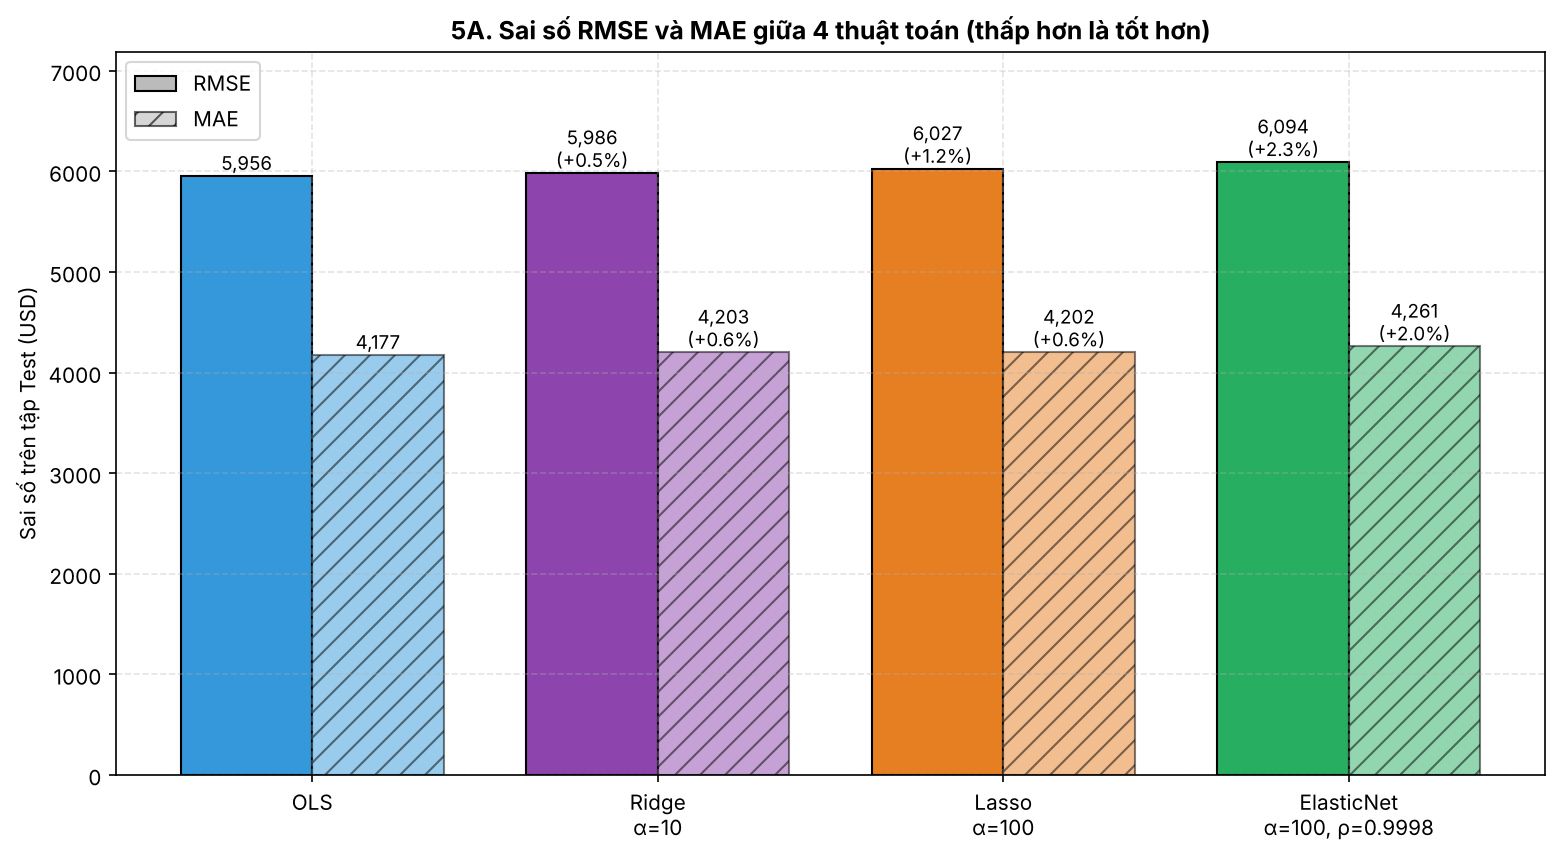

In [12]:
fig, ax = plt.subplots(figsize=(10.5, 5.8), dpi=150)
xp = np.arange(len(MODEL_ORDER))
bw = 0.38
rmse_v = results_num.loc[MODEL_ORDER, "RMSE"].to_numpy()
mae_v = results_num.loc[MODEL_ORDER, "MAE"].to_numpy()
cols = [MODEL_COLORS[k] for k in MODEL_ORDER]
b1 = ax.bar(xp - bw / 2, rmse_v, bw, color=cols, edgecolor="k", label="RMSE")
b2 = ax.bar(xp + bw / 2, mae_v, bw, color=cols, edgecolor="k", alpha=0.5, hatch="//", label="MAE")
for i, (r_, m_) in enumerate(zip(rmse_v, mae_v)):
    d_r = (r_ / rmse_v[0] - 1) * 100
    d_m = (m_ / mae_v[0] - 1) * 100
    ax.text(i - bw / 2, r_ + 60, f"{r_:,.0f}\n({d_r:+.1f}%)" if i else f"{r_:,.0f}", ha="center", fontsize=9)
    ax.text(i + bw / 2, m_ + 60, f"{m_:,.0f}\n({d_m:+.1f}%)" if i else f"{m_:,.0f}", ha="center", fontsize=9)
ax.set_xticks(xp)
ax.set_xticklabels(["OLS", f"Ridge\nα={ALPHA_RIDGE:g}", f"Lasso\nα={ALPHA:g}", f"ElasticNet\nα={ALPHA_EN:g}, ρ={L1_RATIO_EN}"])
ax.set_ylabel("Sai số trên tập Test (USD)")
ax.set_ylim(0, rmse_v.max() * 1.18)
ax.set_title("5A. Sai số RMSE và MAE giữa 4 thuật toán (thấp hơn là tốt hơn)", fontweight="bold")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc="#bbbbbb", ec="k", label="RMSE"),
                   plt.Rectangle((0, 0), 1, 1, fc="#bbbbbb", ec="k", hatch="//", alpha=0.6, label="MAE")],
          loc="upper left")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "5A_rmse_mae_comparison.png")
plt.show()

### Biểu đồ 5B: điểm R² và số trọng số bị loại
Panel trái **cắt trục y ở 0.78** để nhìn thấy chênh lệch (ghi rõ trên hình). Panel phải là số biến bị đưa về 0.

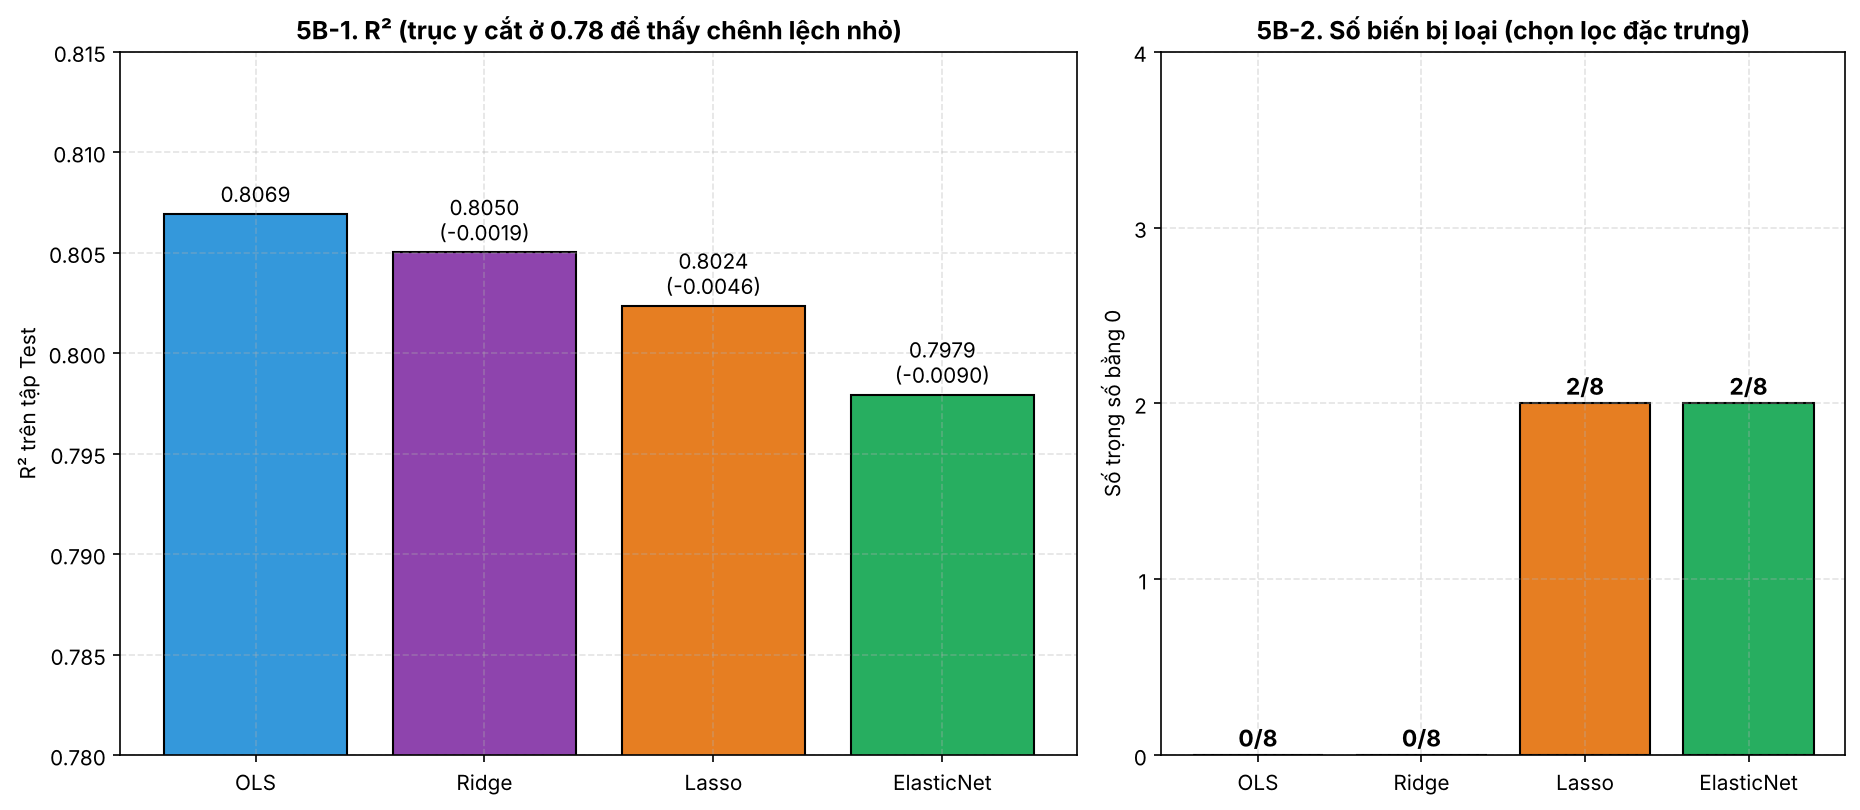

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 5.5), dpi=150, gridspec_kw={"width_ratios": [1.4, 1]})
r2_v = results_num.loc[MODEL_ORDER, "R2"].to_numpy()
ax[0].bar(MODEL_ORDER, r2_v, color=cols, edgecolor="k")
for i, v in enumerate(r2_v):
    ax[0].text(i, v + 0.0006, f"{v:.4f}" + ("" if i == 0 else f"\n({v - r2_v[0]:+.4f})"), ha="center", fontsize=10)
ax[0].set_ylim(0.78, 0.815)
ax[0].set_ylabel("R² trên tập Test")
ax[0].set_title("5B-1. R² (trục y cắt ở 0.78 để thấy chênh lệch nhỏ)", fontweight="bold")

zw = results_num.loc[MODEL_ORDER, "Zero_Weights"].to_numpy()
ax[1].bar(MODEL_ORDER, zw, color=cols, edgecolor="k")
for i, v in enumerate(zw):
    ax[1].text(i, v + 0.05, f"{int(v)}/8", ha="center", fontsize=11, fontweight="bold")
ax[1].set_ylim(0, 4)
ax[1].set_yticks(range(5))
ax[1].set_ylabel("Số trọng số bằng 0")
ax[1].set_title("5B-2. Số biến bị loại (chọn lọc đặc trưng)", fontweight="bold")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "5B_r2_zero_weights.png")
plt.show()

### Biểu đồ 5C: giá trị thực tế vs dự đoán (OLS và ElasticNet)
Mỗi chấm là một người trong tập test, đường đứt là dự đoán hoàn hảo ($\hat y=y$). Màu theo `smoker` vì đây là biến chi phối nhất.

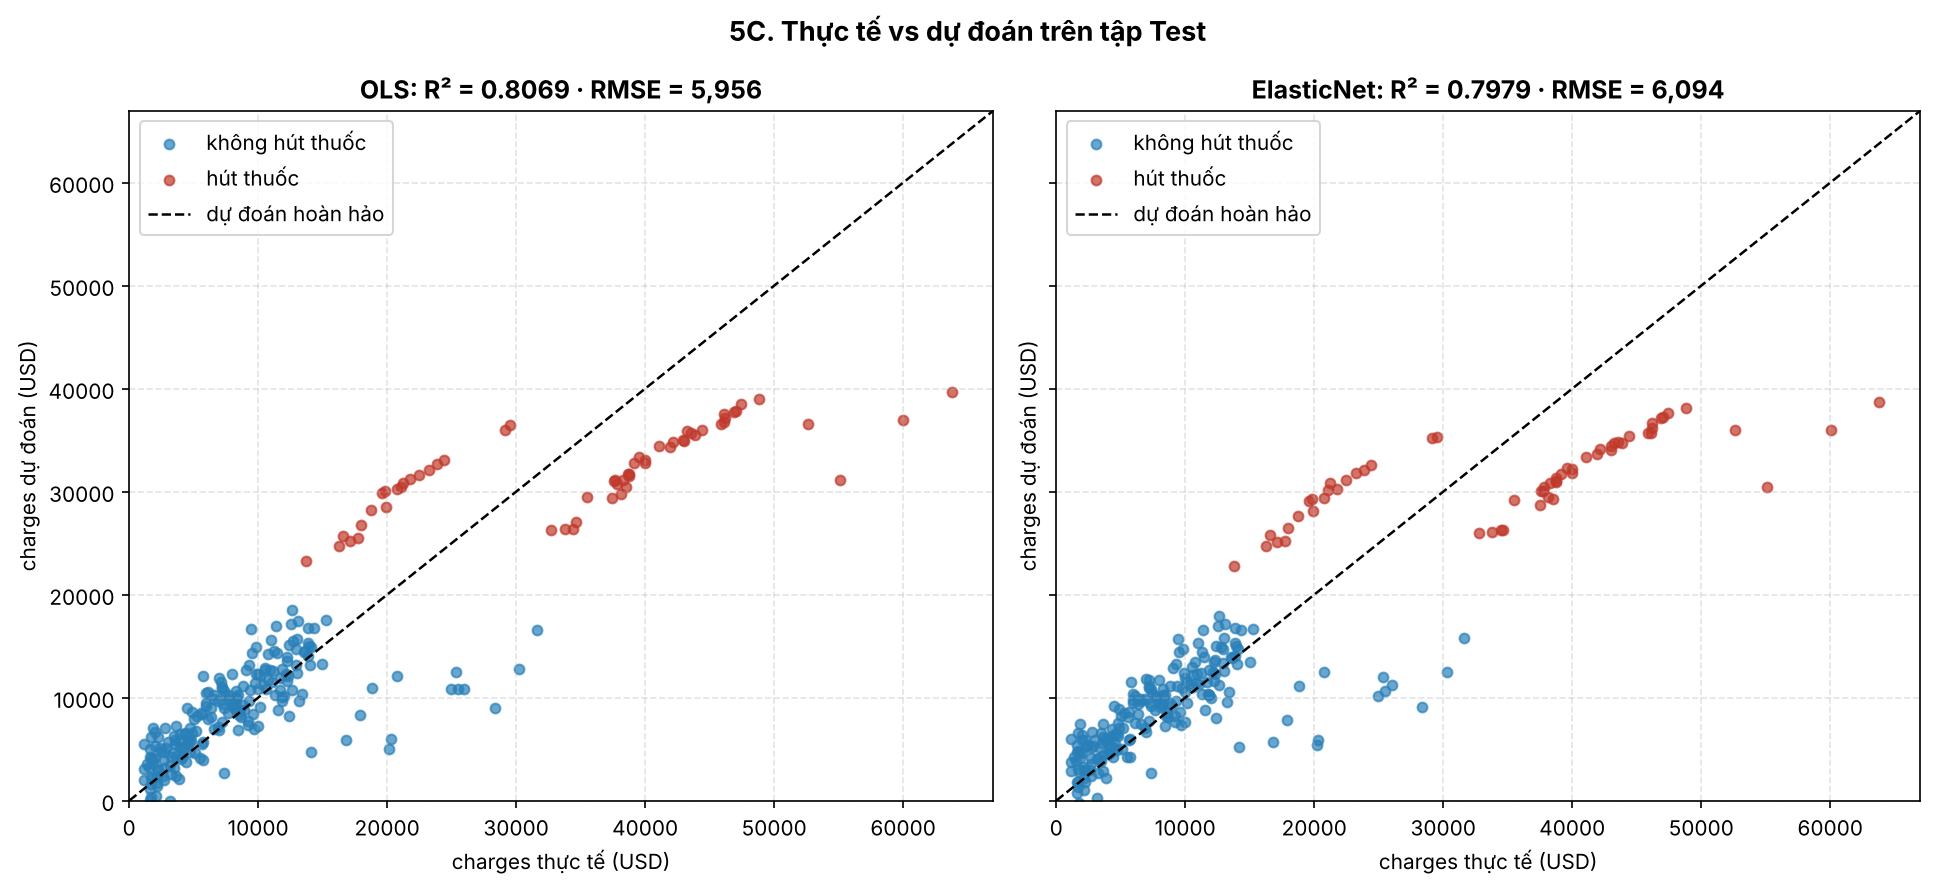

In [14]:
smk = (X_test["smoker"] == "yes").to_numpy()
fig, ax = plt.subplots(1, 2, figsize=(13, 6), dpi=150, sharex=True, sharey=True)
lim = [0, max(y_test.max(), max(p.max() for p in y_pred.values())) * 1.05]
for a, k in zip(ax, ["OLS", "ElasticNet"]):
    a.scatter(y_test[~smk], y_pred[k][~smk], s=22, alpha=0.7, color="#2980b9", label="không hút thuốc")
    a.scatter(y_test[smk], y_pred[k][smk], s=22, alpha=0.7, color="#c0392b", label="hút thuốc")
    a.plot(lim, lim, "k--", lw=1.2, label="dự đoán hoàn hảo")
    a.set_xlim(lim)
    a.set_ylim(lim)
    a.set_xlabel("charges thực tế (USD)")
    a.set_ylabel("charges dự đoán (USD)")
    a.set_title(f"{k}: R² = {results_num.loc[k, 'R2']:.4f} · RMSE = {results_num.loc[k, 'RMSE']:,.0f}", fontweight="bold")
    a.legend(loc="upper left")
fig.suptitle("5C. Thực tế vs dự đoán trên tập Test", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "5C_true_vs_predicted.png")
plt.show()

### Biểu đồ 5D: trọng số $w$ của 4 mô hình
Sắp theo độ lớn của OLS. Chữ đỏ đánh dấu biến bị đưa về 0.

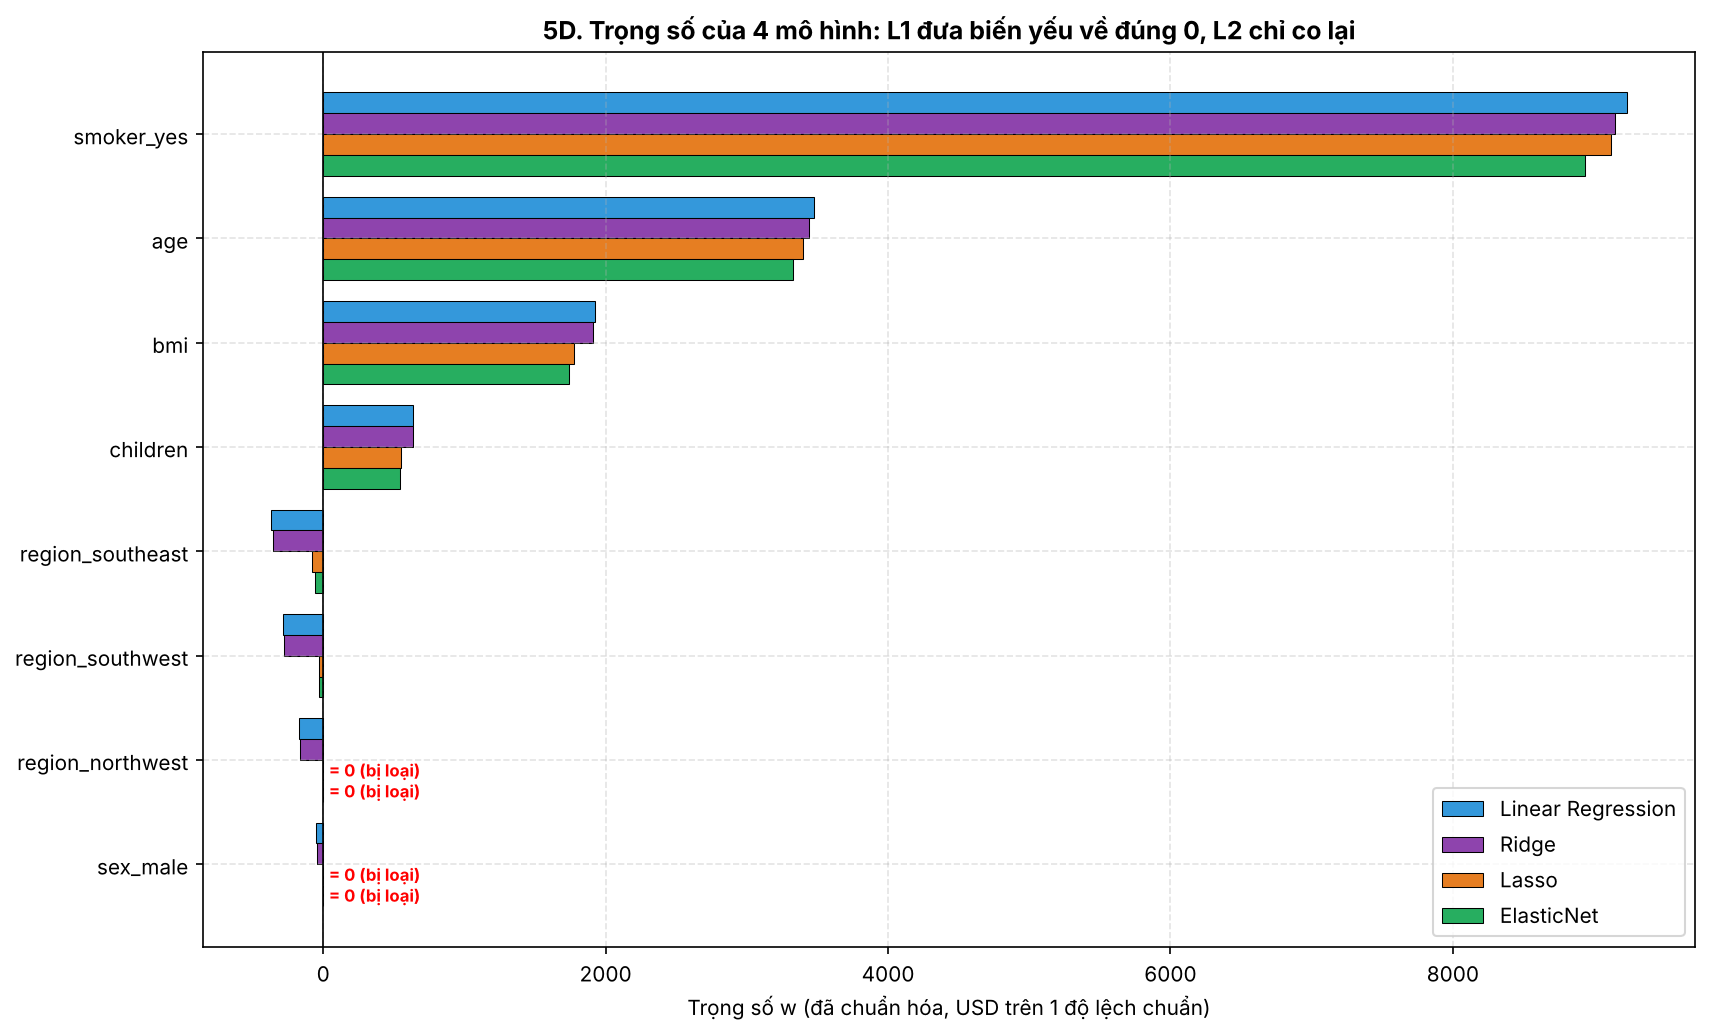

In [15]:
order = W["OLS"].abs().sort_values().index
yy = np.arange(len(order))
bh = 0.2
fig, ax = plt.subplots(figsize=(11.5, 7), dpi=150)
for j, k in enumerate(MODEL_ORDER):
    ax.barh(yy + (1.5 - j) * bh, W.loc[order, k], bh, color=MODEL_COLORS[k], edgecolor="k", lw=0.5, label=MODEL_LABELS[k].split(" (")[0])
for i, f in enumerate(order):
    for j, k in enumerate(MODEL_ORDER):
        if W.loc[f, k] == 0:
            ax.text(40, i + (1.5 - j) * bh, "= 0 (bị loại)", color="red", va="center", fontsize=8, fontweight="bold")
ax.set_yticks(yy)
ax.set_yticklabels(order)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Trọng số w (đã chuẩn hóa, USD trên 1 độ lệch chuẩn)")
ax.set_title("5D. Trọng số của 4 mô hình: L1 đưa biến yếu về đúng 0, L2 chỉ co lại", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "5D_weights_comparison.png")
plt.show()

---
# Phần 4. Phân tích chuyên sâu từng thuật toán
Mỗi mục dưới đây **dùng lại `X_tr`, `X_te`, `models` của Phần 1–2**, không tiền xử lý lại.

## 4.1 Linear Regression (OLS)

**Mô hình:** $\hat y=b+w_1x_1+\dots+w_px_p$. **Tối ưu:** tìm $w,b$ để cực tiểu tổng bình phương phần dư $\sum_i(y_i-\hat y_i)^2$.
OLS có **nghiệm đóng** (phương trình chuẩn): $\hat\beta=(X_b^\top X_b)^{-1}X_b^\top y$, với $X_b$ là $X$ thêm cột 1 cho intercept. Ô dưới tự giải phương trình này và so với sklearn.

In [16]:
Xb = np.c_[np.ones(len(X_tr)), X_tr]                 # thêm cột 1 cho intercept
beta_ne = np.linalg.solve(Xb.T @ Xb, Xb.T @ y_tr)    # giải (XᵀX) beta = Xᵀy
beta_sk = np.r_[ols.intercept_, ols.coef_]
cmp_ols = pd.DataFrame({"Phương trình chuẩn": beta_ne, "sklearn": beta_sk}, index=["intercept"] + feat)
display(cmp_ols.round(2))
print(f"Sai lệch lớn nhất: {np.max(np.abs(beta_ne - beta_sk)):.2e} USD")

,Phương trình chuẩn,sklearn
intercept,"13,030.20","13,030.20"
age,"3,472.98","3,472.98"
bmi,"1,927.83","1,927.83"
children,636.50,636.50
sex_male,-50.75,-50.75
smoker_yes,"9,234.34","9,234.34"
region_northwest,-168.94,-168.94
region_southeast,-371.78,-371.78
region_southwest,-284.61,-284.61


Sai lệch lớn nhất: 3.27e-11 USD


### 4.1.1 Hồi quy đơn biến
Dùng **một** biến gốc (chưa chuẩn hóa) để thấy đường thẳng OLS là gì, rồi so R² với mô hình đủ 8 biến. Mỗi điểm là một người trong tập train.

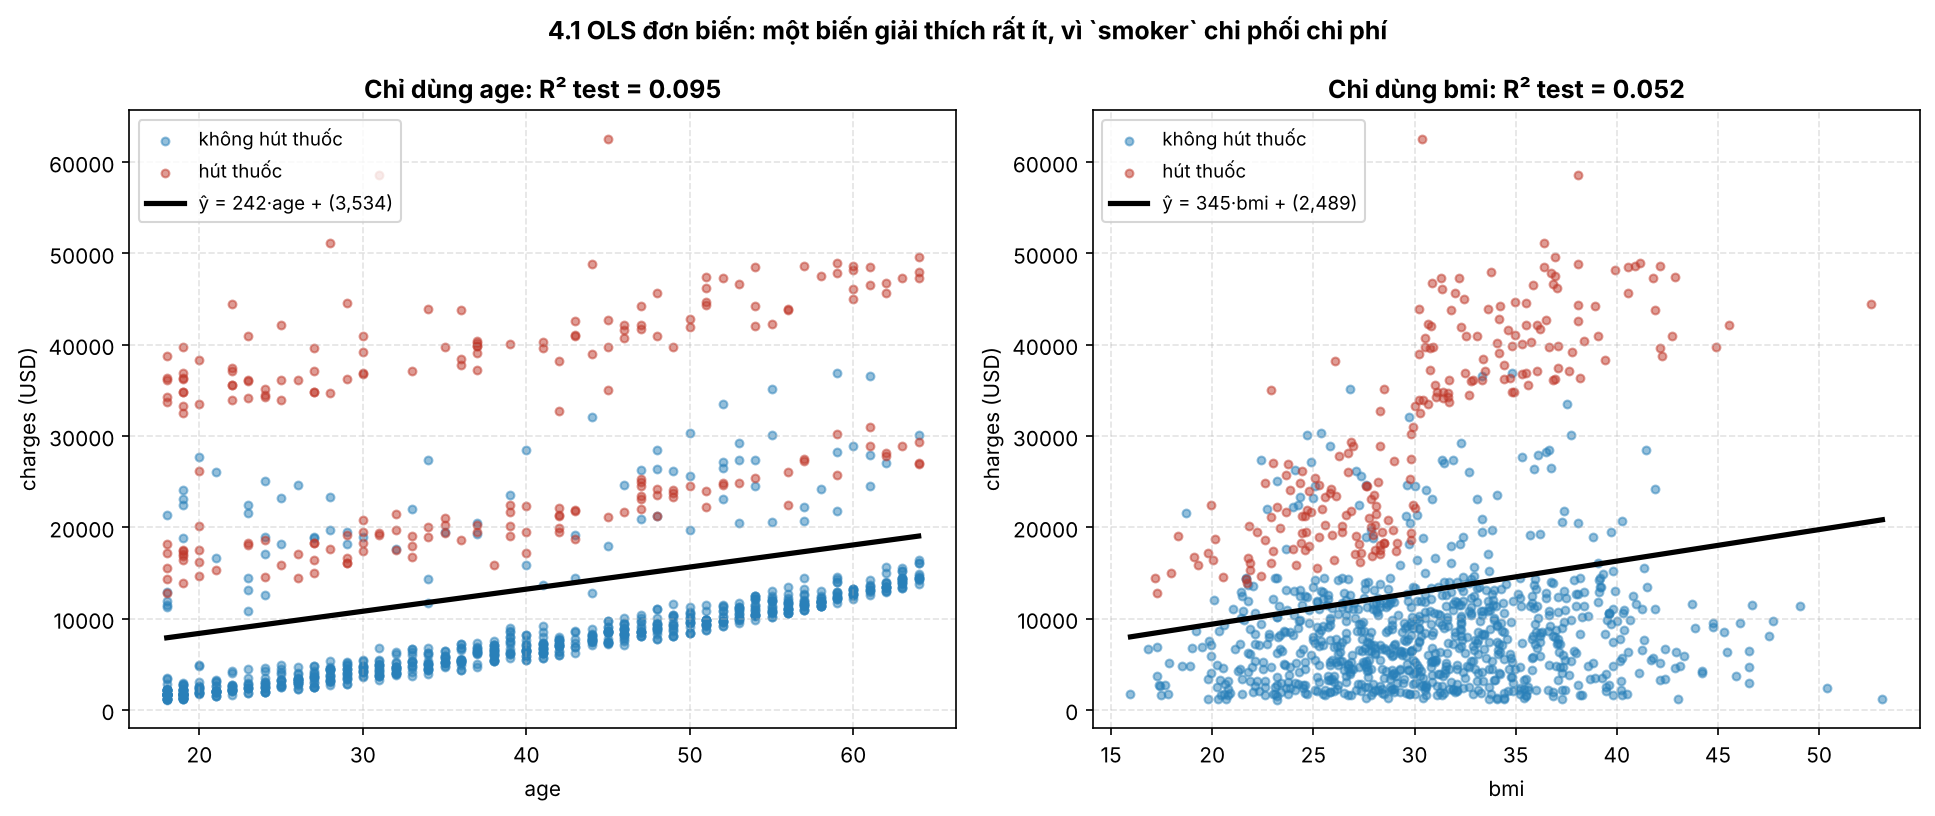

R² test: chỉ age = 0.0951 | chỉ bmi = 0.0517 | đủ 8 biến = 0.8069


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5), dpi=150)
single = {}
for a, col, unit in [(ax[0], "age", "tuổi"), (ax[1], "bmi", "BMI")]:
    m1 = LinearRegression().fit(X_train[[col]], y_train)
    r2_1 = r2_score(y_test, m1.predict(X_test[[col]]))
    single[col] = r2_1
    is_s = (X_train["smoker"] == "yes").to_numpy()
    a.scatter(X_train.loc[~is_s, col], y_train[~is_s], s=14, alpha=0.5, color="#2980b9", label="không hút thuốc")
    a.scatter(X_train.loc[is_s, col], y_train[is_s], s=14, alpha=0.5, color="#c0392b", label="hút thuốc")
    xs_ = np.linspace(X_train[col].min(), X_train[col].max(), 100)
    a.plot(xs_, m1.predict(pd.DataFrame({col: xs_})), color="k", lw=2.5,
           label=f"ŷ = {m1.coef_[0]:,.0f}·{col} + ({m1.intercept_:,.0f})")
    a.set_xlabel(col)
    a.set_ylabel("charges (USD)")
    a.set_title(f"Chỉ dùng {col}: R² test = {r2_1:.3f}", fontweight="bold")
    a.legend(loc="upper left", fontsize=9)
fig.suptitle("4.1 OLS đơn biến: một biến giải thích rất ít, vì `smoker` chi phối chi phí", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "4.1_ols_univariate.png")
plt.show()
print(f"R² test: chỉ age = {single['age']:.4f} | chỉ bmi = {single['bmi']:.4f} | đủ 8 biến = {results_num.loc['OLS', 'R2']:.4f}")

### 4.1.2 Phân tích phần dư (mô hình OLS đủ 8 biến, tập test)
Phần dư $e_i=y_i-\hat y_i$. OLS lý tưởng khi phần dư có trung bình 0, phương sai đều theo $\hat y$ và gần phân phối chuẩn. Ba hình: phần dư theo giá trị dự đoán, histogram, Q-Q plot.

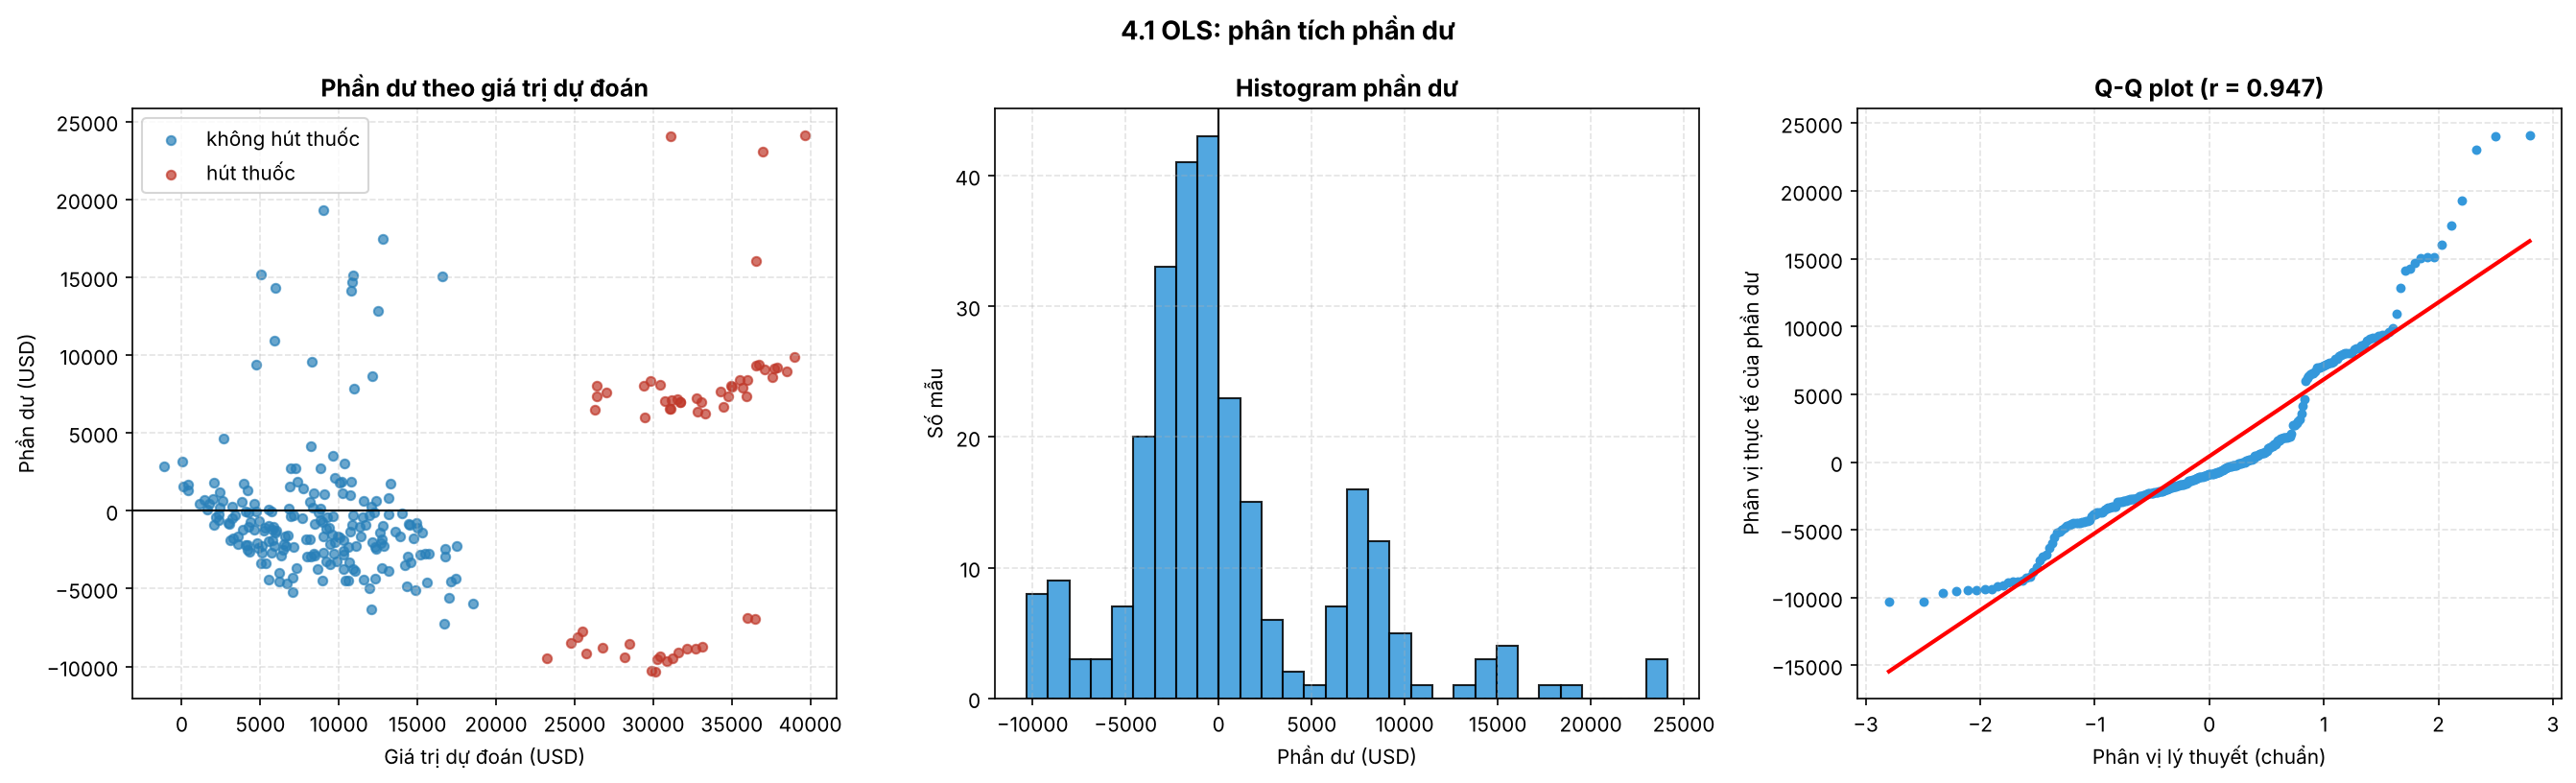

Trung bình phần dư = 425.3 | độ lệch chuẩn = 5,941.1 | độ lệch (skew) = 1.24 | độ nhọn dư (kurtosis) = 2.29
Độ lệch chuẩn phần dư theo từng tứ phân vị của giá trị dự đoán:


,std phần dư (USD)
Q1 (thấp),"3,556.93"
Q2,"3,551.15"
Q3,"5,432.88"
Q4 (cao),"9,107.56"


Phần dư trung bình theo nhóm hút thuốc:


,mean,std,count
hút thuốc,"3,129.26","9,335.13",60
không hút,-354.74,"4,257.90",208


In [18]:
resid = (y_test - y_pred["OLS"]).to_numpy()
fitted = y_pred["OLS"]

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5), dpi=150)
ax[0].scatter(fitted[~smk], resid[~smk], s=20, alpha=0.7, color="#2980b9", label="không hút thuốc")
ax[0].scatter(fitted[smk], resid[smk], s=20, alpha=0.7, color="#c0392b", label="hút thuốc")
ax[0].axhline(0, color="k", lw=1)
ax[0].set_xlabel("Giá trị dự đoán (USD)")
ax[0].set_ylabel("Phần dư (USD)")
ax[0].set_title("Phần dư theo giá trị dự đoán", fontweight="bold")
ax[0].legend()

ax[1].hist(resid, bins=30, color="#3498db", edgecolor="k", alpha=0.85)
ax[1].axvline(0, color="k", lw=1)
ax[1].set_xlabel("Phần dư (USD)")
ax[1].set_ylabel("Số mẫu")
ax[1].set_title("Histogram phần dư", fontweight="bold")

(osm, osr), (slope, intercept, r_qq) = stats.probplot(resid, dist="norm")
ax[2].scatter(osm, osr, s=14, color="#3498db")
ax[2].plot(osm, slope * osm + intercept, "r-", lw=2)
ax[2].set_xlabel("Phân vị lý thuyết (chuẩn)")
ax[2].set_ylabel("Phân vị thực tế của phần dư")
ax[2].set_title(f"Q-Q plot (r = {r_qq:.3f})", fontweight="bold")
fig.suptitle("4.1 OLS: phân tích phần dư", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "4.1_ols_residuals.png")
plt.show()

q = pd.qcut(fitted, 4, labels=["Q1 (thấp)", "Q2", "Q3", "Q4 (cao)"])
print(f"Trung bình phần dư = {resid.mean():,.1f} | độ lệch chuẩn = {resid.std():,.1f} | độ lệch (skew) = {stats.skew(resid):.2f} | độ nhọn dư (kurtosis) = {stats.kurtosis(resid):.2f}")
print("Độ lệch chuẩn phần dư theo từng tứ phân vị của giá trị dự đoán:")
display(pd.Series(resid).groupby(q, observed=True).std().rename("std phần dư (USD)").to_frame())
print("Phần dư trung bình theo nhóm hút thuốc:")
display(pd.Series(resid).groupby(np.where(smk, "hút thuốc", "không hút")).agg(["mean", "std", "count"]))

**Đọc kết quả phần dư** (số liệu từ ô trên)
- Trung bình phần dư ≈ +425 USD và độ lệch (skew) = 1.24: phân phối **lệch phải**, có đuôi dài là những người bị đánh giá thấp chi phí rất nhiều.
- Phương sai **không đều**: độ lệch chuẩn phần dư tăng từ khoảng 3,550 USD (hai tứ phân vị thấp) lên 5,433 (Q3) và 9,108 (Q4). Đây là dấu hiệu vi phạm giả định phương sai đồng nhất của OLS.
- Nhóm hút thuốc bị **dự đoán thấp** (phần dư trung bình +3,129 USD, độ lệch chuẩn 9,335) còn nhóm không hút thuốc bị dự đoán cao nhẹ (−355 USD). Trên hình, nhóm hút thuốc tách thành **hai cụm** (một cụm dự đoán thấp khoảng +7,000, một cụm dự đoán cao khoảng −9,000), nên trung bình che mất cấu trúc. Mô hình tuyến tính cộng gộp không bắt được việc ảnh hưởng của `bmi` và `age` khác nhau giữa hai nhóm (tương tác), nên đây là hạn chế cấu trúc của cả 4 mô hình tuyến tính, không riêng OLS.
- Hệ quả cho báo cáo: hệ số OLS vẫn dùng để so sánh các mô hình, nhưng khoảng tin cậy/p-value suy ra từ giả định chuẩn sẽ không đáng tin ở dataset này.

## 4.2 Ridge Regression (L2)

**Ý tưởng:** thêm phạt $\alpha\sum w_j^2$ để kìm hãm trọng số lớn. Nghiệm đóng: $\hat w=(X^\top X+\alpha I)^{-1}X^\top(y-\bar y)$ (X đã chuẩn hóa nên intercept $=\bar y$ và không bị phạt). Thêm $\alpha I$ làm ma trận luôn khả nghịch, đó là lý do Ridge xử lý được đa cộng tuyến.
Ô dưới kiểm chứng công thức bằng tay so với `Ridge(alpha=10)`.

In [19]:
p_ = X_tr.shape[1]
w_ridge_cf = np.linalg.solve(X_tr.T @ X_tr + ALPHA_RIDGE * np.eye(p_), X_tr.T @ (y_tr - y_tr.mean()))
cmp_r = pd.DataFrame({"Công thức đóng": w_ridge_cf, "sklearn Ridge": ridge.coef_}, index=feat)
display(cmp_r.round(2))
print(f"Sai lệch lớn nhất: {np.max(np.abs(w_ridge_cf - ridge.coef_)):.2e} USD")

,Công thức đóng,sklearn Ridge
age,"3,440.44","3,440.44"
bmi,"1,907.35","1,907.35"
children,634.44,634.44
sex_male,-42.92,-42.92
smoker_yes,"9,145.51","9,145.51"
region_northwest,-165.80,-165.80
region_southeast,-353.35,-353.35
region_southwest,-277.49,-277.49


Sai lệch lớn nhất: 1.82e-12 USD


### 4.2.1 VIF: dữ liệu này có đa cộng tuyến nặng không?
$\text{VIF}_j$ là phần tử đường chéo của nghịch đảo ma trận tương quan. Quy ước thường dùng: VIF > 5 (hoặc 10) là đa cộng tuyến đáng lo.

In [20]:
corr = np.corrcoef(X_tr.T)
vif = pd.Series(np.diag(np.linalg.inv(corr)), index=feat, name="VIF")
display(vif.to_frame().T.round(2))
print(f"VIF lớn nhất = {vif.max():.2f} ({vif.idxmax()})")
print("Tương quan giữa 3 biến region:")
display(pd.DataFrame(corr, index=feat, columns=feat).loc[["region_northwest", "region_southeast", "region_southwest"],
                                                          ["region_northwest", "region_southeast", "region_southwest"]].round(2))

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
VIF,1.02,1.11,1.00,1.01,1.02,1.54,1.68,1.56


VIF lớn nhất = 1.68 (region_southeast)
Tương quan giữa 3 biến region:


,region_northwest,region_southeast,region_southwest
region_northwest,1.00,-0.35,-0.33
region_southeast,-0.35,1.00,-0.35
region_southwest,-0.33,-0.35,1.00


### 4.2.2 Coefficient Path và chọn alpha bằng CV
Alpha chạy từ $10^{-2}$ đến $10^{4}$ (thang log). Đường đỏ đứt đánh dấu $\alpha=10$ (giá trị chuẩn của nhóm). **Panel trái:** hệ số co lại khi alpha tăng. **Panel phải:** RMSE của 5-fold CV trên Train theo alpha (không dùng Test); trục y được cắt để thấy vùng gần đáy.

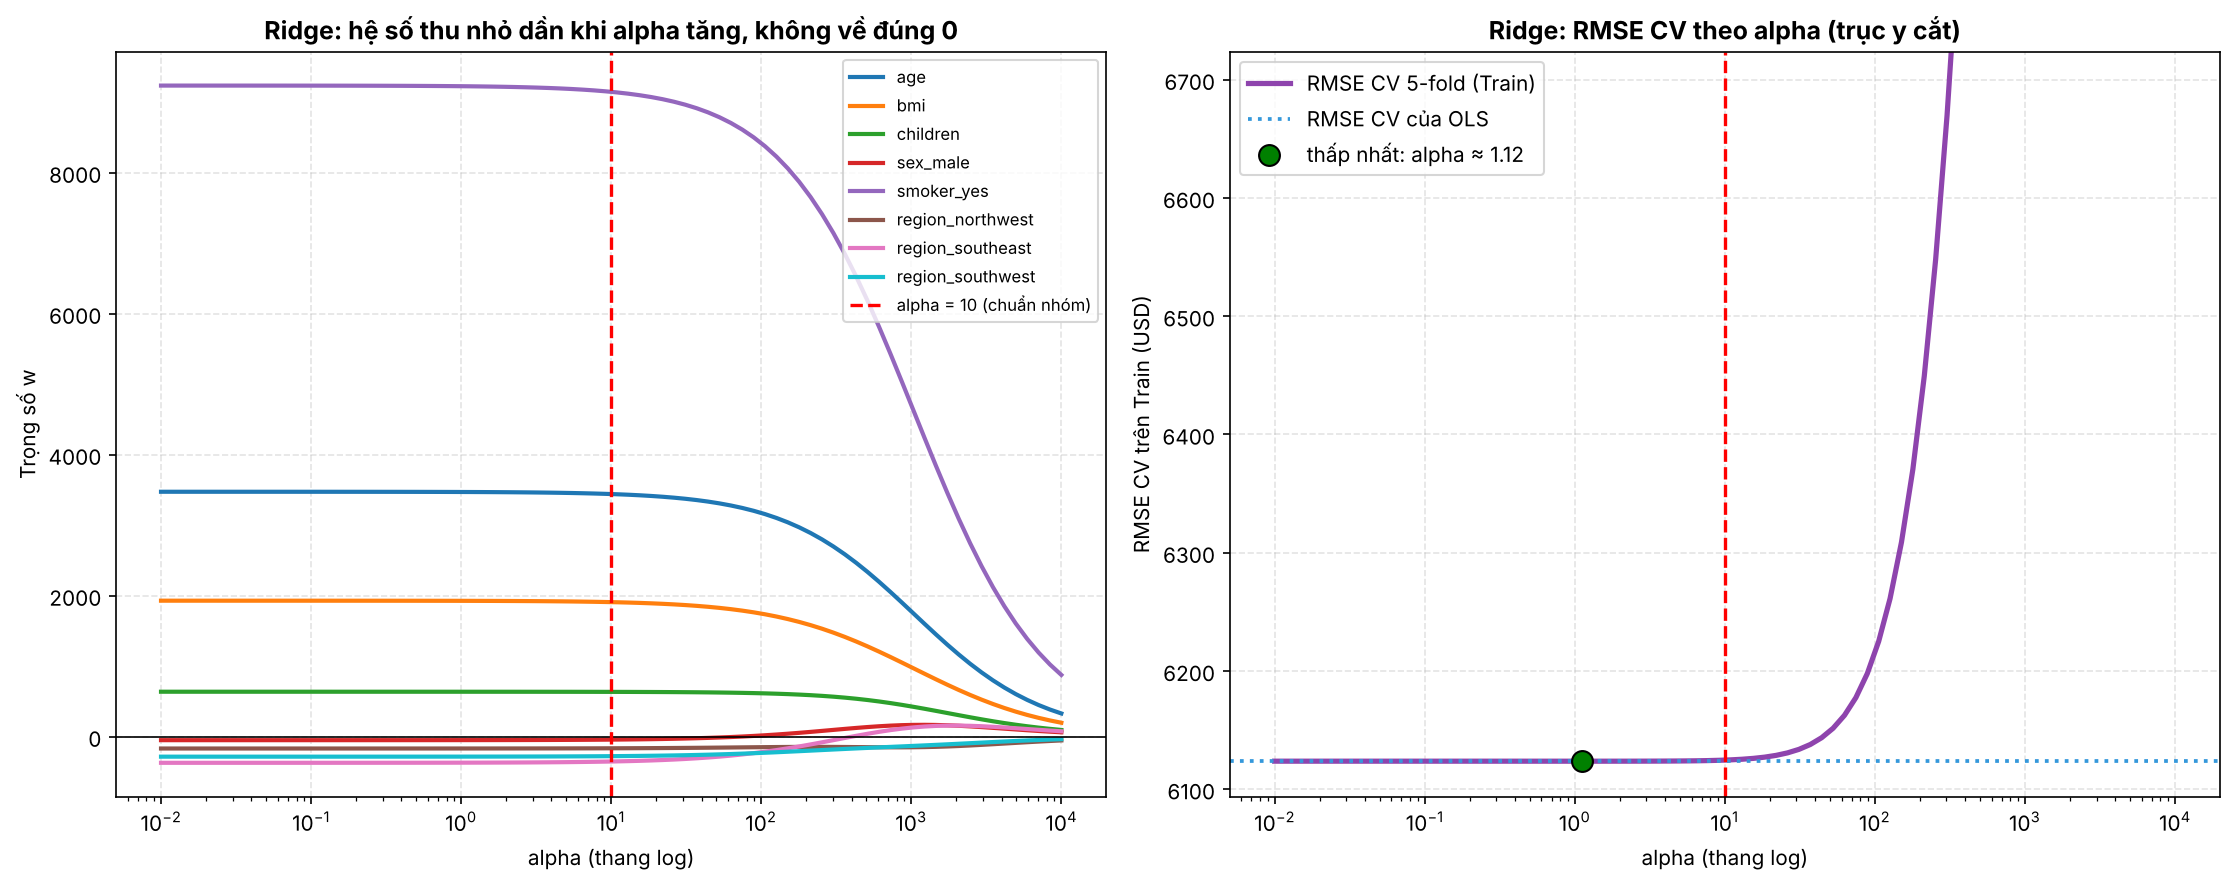

Ridge: RMSE CV thấp nhất ở alpha ≈ 1.12 (6,123.64 USD) | alpha = 10: 6,124.56 USD | OLS: 6,123.65 USD
|w| nhỏ nhất của từng biến trên toàn dải alpha (đều > 0, Ridge không triệt tiêu):


,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
min |w|,328.19,196.63,94.33,1.15,874.79,54.40,10.94,36.74


In [21]:
ridge_alphas = np.logspace(-2, 4, 80)
ridge_coefs = np.array([Ridge(alpha=a).fit(X_tr, y_train).coef_ for a in ridge_alphas])

ridge_cv = []
for a in ridge_alphas:
    r = cv_scores(Ridge(alpha=a))
    ridge_cv.append({"alpha": a, "cv_rmse": -r["test_rmse"].mean(), "cv_r2": r["test_r2"].mean()})
ridge_cv = pd.DataFrame(ridge_cv)
ridge_cv.to_csv(OUT_DIR / "ridge_alpha_cv.csv", index=False)
ridge_best = ridge_cv.loc[ridge_cv["cv_rmse"].idxmin()]

fig, ax = plt.subplots(1, 2, figsize=(15, 6), dpi=150)
for i, f in enumerate(feat):
    ax[0].plot(ridge_alphas, ridge_coefs[:, i], lw=2, color=COLORS[f], label=f)
ax[0].set_xscale("log")
ax[0].axhline(0, color="k", lw=0.8)
ax[0].axvline(ALPHA_RIDGE, color="red", ls="--", lw=1.6, label=f"alpha = {ALPHA_RIDGE:g} (chuẩn nhóm)")
ax[0].set_xlabel("alpha (thang log)")
ax[0].set_ylabel("Trọng số w")
ax[0].set_title("Ridge: hệ số thu nhỏ dần khi alpha tăng, không về đúng 0", fontweight="bold")
ax[0].legend(fontsize=8, loc="upper right")

ax[1].plot(ridge_cv["alpha"], ridge_cv["cv_rmse"], color="#8e44ad", lw=2.5, label="RMSE CV 5-fold (Train)")
ax[1].axhline(cv_table.loc["OLS", "CV RMSE"], color=MODEL_COLORS["OLS"], ls=":", lw=1.8, label="RMSE CV của OLS")
ax[1].plot(ridge_best["alpha"], ridge_best["cv_rmse"], "o", color="green", ms=10, mec="k",
           label=f"thấp nhất: alpha ≈ {ridge_best['alpha']:.2f}")
ax[1].axvline(ALPHA_RIDGE, color="red", ls="--", lw=1.6)
ax[1].set_xscale("log")
ax[1].set_ylim(ridge_best["cv_rmse"] - 30, ridge_best["cv_rmse"] + 600)
ax[1].set_xlabel("alpha (thang log)")
ax[1].set_ylabel("RMSE CV trên Train (USD)")
ax[1].set_title("Ridge: RMSE CV theo alpha (trục y cắt)", fontweight="bold")
ax[1].legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / "4.2_ridge_coefficient_path.png")
plt.show()

print(f"Ridge: RMSE CV thấp nhất ở alpha ≈ {ridge_best['alpha']:.2f} ({ridge_best['cv_rmse']:,.2f} USD) | "
      f"alpha = {ALPHA_RIDGE:g}: {cv_table.loc['Ridge', 'CV RMSE']:,.2f} USD | OLS: {cv_table.loc['OLS', 'CV RMSE']:,.2f} USD")
smallest = np.abs(ridge_coefs).min(axis=0)
print("|w| nhỏ nhất của từng biến trên toàn dải alpha (đều > 0, Ridge không triệt tiêu):")
display(pd.Series(smallest, index=feat, name="min |w|").to_frame().T.round(3))

**Đọc kết quả.** RMSE CV của Ridge gần như phẳng ở alpha nhỏ: khoảng 6,123.64 ở alpha ≈ 1.12, 6,124.56 ở alpha = 10 và 6,123.65 với OLS (chênh dưới 1 USD), rồi chỉ tăng rõ khi alpha lớn. Vì VIF thấp (mục 4.2.1), OLS không bị đa cộng tuyến nặng nên Ridge không có nhiều thứ để cải thiện. $\alpha=10$ là cấu hình nhóm chọn để minh họa, không phải alpha tối ưu tuyệt đối.

## 4.3 Lasso Regression (L1) 
Toàn bộ phần phân tích chuyên sâu của Lasso giữ nguyên, chạy trên cùng `X_tr`/`X_te` và mô hình `las` ($\alpha=100$) ở Phần 2. Thứ tự: lý thuyết, đọc kết quả, Coordinate Descent, KKT, Lasso path, chọn alpha, Hình 1–4.

### 4.3.1 Lý thuyết Lasso 

**Hàm mục tiêu** (đúng với `sklearn.linear_model.Lasso`):

$$\min_{w,b}\ \frac{1}{2n}\sum_{i=1}^{n}\big(y_i-\hat y_i\big)^2\;+\;\alpha\sum_{j=1}^{p}|w_j|,\qquad \hat y_i=b+\sum_j w_j x_{ij}$$

| Thành phần | Ý nghĩa |
| :--- | :--- |
| Số hạng đầu | MSE (chia 2n), đo độ khớp dữ liệu |
| $\alpha\sum\lvert w_j\rvert$ | **Phạt L1**: tổng giá trị tuyệt đối trọng số |
| $\alpha$ | Độ mạnh của phạt. $\alpha\to 0$ là OLS. $\alpha$ lớn thì nhiều $w_j=0$ |
| $b$ (intercept) | Không bị phạt. Khi X đã chuẩn hóa thì $b=\overline{y}_{train}$ |

**So với Ridge và OLS**

| | OLS | Ridge (L2) | Lasso (L1) |
| :--- | :--- | :--- | :--- |
| Phạt | không | $\alpha\sum w_j^2$ | $\alpha\sum\lvert w_j\rvert$ |
| Trọng số | giữ nguyên | co đều, không về 0 | co và **đưa một số về đúng 0** |
| Chọn biến | không | không | **có** |

**Lưu ý về $\alpha$:** sklearn chia MSE cho $2n$. Nếu slide viết $\lVert y-Xw\rVert^2+\lambda\lVert w\rVert_1$ (không chia) thì $\lambda=2n\alpha$. Với $n=1069$, $\alpha=100$ tương đương $\lambda\approx 213{,}800$.

### 4.3.2 OLS và Lasso: đọc kết quả
Lấy từ bảng chuẩn ở Phần 2 (cùng một lần tiền xử lý), không huấn luyện lại.

In [22]:
print("OLS vs Lasso trên tập Test:")
display(results_num.loc[["OLS", "Lasso"]].round(4))
print("Trọng số w (sau StandardScaler):")
display(W[["OLS", "Lasso"]].round(2))
print(f"Intercept Lasso = {las.intercept_:,.2f}  (bằng mean(y_train) = {y_tr.mean():,.2f})")

OLS vs Lasso trên tập Test:


,MSE,RMSE,MAE,R2,Zero_Weights
Model,,,,,
OLS,"35,478,020.68","5,956.34","4,177.05",0.81,0
Lasso,"36,319,178.48","6,026.54","4,202.30",0.80,2


Trọng số w (sau StandardScaler):


,OLS,Lasso
Feature,,
age,"3,472.98","3,395.69"
bmi,"1,927.83","1,776.97"
children,636.50,547.36
sex_male,-50.75,0.00
smoker_yes,"9,234.34","9,121.86"
region_northwest,-168.94,0.00
region_southeast,-371.78,-80.01
region_southwest,-284.61,-31.81


Intercept Lasso = 13,030.20  (bằng mean(y_train) = 13,030.20)


**Đọc kết quả**
- Lasso giữ **6/8 biến**, đưa `sex_male` và `region_northwest` về **đúng 0**.
- R² giảm rất ít (0.8069 → 0.8024) đổi lấy mô hình gọn hơn.
- `smoker_yes`, `age`, `bmi` vẫn là ba biến mạnh nhất. `region_southeast`, `region_southwest` bị co rất mạnh về gần 0.
- Đổi sang đơn vị thật (chia w cho độ lệch chuẩn của biến) ở ô dưới.

In [23]:
sd = pd.Series(preprocessor.named_steps["scale"].scale_, index=feat)
real = pd.DataFrame({"w Lasso (đã chuẩn hóa)": W["Lasso"], "std của biến": sd, "USD trên 1 đơn vị biến": W["Lasso"] / sd})
real.round(2)

,w Lasso (đã chuẩn hóa),std của biến,USD trên 1 đơn vị biến
age,"3,395.69",13.99,242.69
bmi,"1,776.97",6.05,293.76
children,547.36,1.19,458.36
sex_male,0.00,0.50,0.00
smoker_yes,"9,121.86",0.40,"22,796.67"
region_northwest,0.00,0.43,0.00
region_southeast,-80.01,0.44,-180.54
region_southwest,-31.81,0.43,-73.67


### 4.3.3 Giải thuật Lasso: Coordinate Descent tự cài 

Vì $|w|$ không khả vi tại 0 nên **không có nghiệm đóng** như OLS. sklearn lặp từng biến một, mỗi bước có nghiệm đóng gọi là **soft-thresholding**:

$$S(z,\alpha)=\operatorname{sign}(z)\cdot\max(|z|-\alpha,\,0)$$

**Thuật toán** (với X đã chuẩn hóa nên $x_j^\top x_j/n=1$):
1. Khởi tạo $w=0$, phần dư $r=y-\overline y$.
2. Với mỗi biến $j$: cộng lại đóng góp cũ của $j$ vào $r$ → tính $\rho_j=\frac1n x_j^\top r$ → $w_j=S(\rho_j,\alpha)$ → trừ đóng góp mới của $j$ khỏi $r$.
3. Lặp bước 2 cho tới khi $w$ không đổi.

Nếu $|\rho_j|\le\alpha$ thì $w_j=0$: biến đó không đủ "sức" thắng phạt. Hàm mục tiêu là hàm lồi nên thuật toán hội tụ tới tối ưu toàn cục.

In [24]:
def soft_threshold(z, a):
    return np.sign(z) * np.maximum(np.abs(z) - a, 0.0)

def lasso_cd(Xs, ys, alpha, n_iter=5000, tol=1e-10):
    # min (1/2n)||y - Xw||^2 + alpha*||w||_1  (cùng hàm mục tiêu với sklearn)
    m, p = Xs.shape
    w = np.zeros(p)
    r = ys - ys.mean()                    # phần dư ban đầu (intercept = mean(y))
    for _ in range(n_iter):
        w_old = w.copy()
        for j in range(p):
            r += Xs[:, j] * w[j]          # bỏ đóng góp của biến j
            rho = Xs[:, j] @ r / m        # tương quan giữa x_j và phần dư
            w[j] = soft_threshold(rho, alpha) / (Xs[:, j] @ Xs[:, j] / m)
            r -= Xs[:, j] * w[j]          # cộng lại với w_j mới
        if np.max(np.abs(w - w_old)) < tol:
            break
    return w

w_cd = lasso_cd(X_tr, y_tr, ALPHA)
las_tight = Lasso(alpha=ALPHA, tol=1e-12, max_iter=500000).fit(X_tr, y_train)   # sklearn hội tụ chặt để so
cmp = pd.DataFrame({"Tự cài (CD)": w_cd, "sklearn": las_tight.coef_}, index=feat)
display(cmp.round(2))
print(f"Sai lệch lớn nhất giữa hai bản: {np.max(np.abs(w_cd - las_tight.coef_)):.2e} USD")

,Tự cài (CD),sklearn
age,"3,395.66","3,395.66"
bmi,"1,777.02","1,777.02"
children,547.36,547.36
sex_male,-0.00,-0.00
smoker_yes,"9,121.88","9,121.88"
region_northwest,-0.00,-0.00
region_southeast,-80.05,-80.05
region_southwest,-31.82,-31.82


Sai lệch lớn nhất giữa hai bản: 8.07e-10 USD


### 4.3.4 Kiểm chứng điều kiện KKT (bằng chứng toán học cho w = 0)

Đặt $g_j=\frac1n x_j^\top(y-\hat y)$ (tương quan của biến $j$ với phần dư). Điều kiện tối ưu của Lasso:

$$w_j\neq 0 \;\Rightarrow\; g_j=\alpha\cdot\operatorname{sign}(w_j),\qquad w_j=0 \;\Rightarrow\; |g_j|\le\alpha$$

Bảng dưới kiểm tra với $\alpha=100$. Biến giữ lại phải có $|g_j|=100$, biến bị loại phải có $|g_j|\le100$. (Lệch nhỏ như 99.97 là sai số hội tụ của solver.)

In [25]:
grad = X_tr.T @ (y_tr - las.predict(X_tr)) / n
kkt = pd.DataFrame({"w_Lasso": las.coef_, "g_j": grad, "abs(g_j)": np.abs(grad)}, index=feat)
zero = np.abs(las.coef_) < 1e-4
kkt["Điều kiện"] = np.where(zero, f"abs(g) <= {ALPHA:g}", f"abs(g) = {ALPHA:g}")
kkt["Thỏa"] = np.where(zero, kkt["abs(g_j)"] <= ALPHA + 1e-6, np.abs(kkt["abs(g_j)"] - ALPHA) < 0.5)
kkt.round(2)

,w_Lasso,g_j,abs(g_j),Điều kiện,Thỏa
age,"3,395.69",99.97,99.97,abs(g) = 100,True
bmi,"1,776.97",100.04,100.04,abs(g) = 100,True
children,547.36,100.00,100.00,abs(g) = 100,True
sex_male,-0.00,-34.29,34.29,abs(g) <= 100,True
smoker_yes,"9,121.86",100.01,100.01,abs(g) = 100,True
region_northwest,-0.00,-5.95,5.95,abs(g) <= 100,True
region_southeast,-80.01,-100.02,100.02,abs(g) = 100,True
region_southwest,-31.81,-100.00,100.00,abs(g) = 100,True


**Điểm hay bị hỏi:** `region_northwest` có $w_{OLS}=-168.94$, lớn hơn $\alpha=100$, vậy mà $w=0$. Công thức $w=S(w_{OLS},\alpha)$ chỉ đúng khi các biến **trực giao**. Ba biến `region` tương quan với nhau (khoảng −0.33 đến −0.35), nên Lasso xét tương quan với *phần dư sau khi đã tính các biến khác*, và con số đó chỉ còn $|g|=5.95<100$. Vì vậy đừng nói "w_Lasso = w_OLS − 100" cho mọi biến.

### 4.3.5 Lasso path, ngưỡng alpha và chọn alpha
#### 4.3.5a Lasso path và alpha khiến từng biến rơi về 0
`lasso_path` giải Lasso cho cả dãy alpha. Với mỗi biến, ta tìm alpha nhỏ nhất làm $w_j=0$ bằng chia đôi (bisection). `alpha_max` là mức mà mọi $w=0$.

In [26]:
alphas_p, coefs_p, _ = lasso_path(X_tr, y_train, alphas=np.logspace(-1, 4.1, 1500), max_iter=50000)
la = np.log10(alphas_p)

def death_alpha(j, lo=1e-1, hi=2e4):
    # alpha nhỏ nhất làm w_j = 0 (chia đôi)
    for _ in range(40):
        mid = np.sqrt(lo * hi)
        c = Lasso(alpha=mid, tol=1e-12, max_iter=200000).fit(X_tr, y_train).coef_[j]
        lo, hi = (mid, hi) if abs(c) > 1e-8 else (lo, mid)
    return hi

zero_at = {f: death_alpha(i) for i, f in enumerate(feat)}
thr = pd.Series(zero_at, name="Bị loại khi alpha lớn hơn").sort_values()
display(thr.to_frame().round(1))
alpha_max = np.abs(X_tr.T @ (y_tr - y_tr.mean()) / n).max()
print(f"alpha_max = {alpha_max:,.1f}  (từ mức này mọi w = 0, mô hình chỉ còn dự đoán trung bình {y_tr.mean():,.2f})")

,Bị loại khi alpha lớn hơn
sex_male,43.50
region_northwest,53.80
region_southwest,119.30
region_southeast,148.80
children,691.10
bmi,"2,031.50"
age,"3,602.50"
smoker_yes,"9,058.10"


alpha_max = 9,058.2  (từ mức này mọi w = 0, mô hình chỉ còn dự đoán trung bình 13,030.20)


Thứ tự bị loại: biến yếu rời trước (`sex_male`, `region_northwest`), `smoker_yes` rời cuối. $\alpha=100$ nằm ngay dưới ngưỡng của `region_southwest` (≈119), nên đúng 2 biến bị loại.

#### 4.3.5b Chọn alpha bằng cross-validation
Dùng 5-fold CV trên **tập Train** bằng `Pipeline` (mục 2.5) cho lưới 100 giá trị alpha từ 0.1 đến 1000 (`np.logspace(-1, 3, 100)`). Test không được dùng để chọn alpha.

In [27]:
cv_alphas = np.logspace(-1, 3, 100)
rows = []
for a in cv_alphas:
    r = cv_scores(Lasso(alpha=a, max_iter=MAX_ITER))
    rows.append({"alpha": a, "cv_rmse": -r["test_rmse"].mean(), "cv_rmse_sd": r["test_rmse"].std(ddof=1),
                 "cv_r2": r["test_r2"].mean()})
lasso_cv_tab = pd.DataFrame(rows)
lasso_cv_tab.to_csv(OUT_DIR / "lasso_alpha_cv.csv", index=False)
best_row = lasso_cv_tab.loc[lasso_cv_tab["cv_rmse"].idxmin()]
cv_best_alpha = float(best_row["alpha"])
las_best = Lasso(alpha=cv_best_alpha, max_iter=MAX_ITER).fit(X_tr, y_train)
print(f"Alpha có CV RMSE thấp nhất trong lưới: {cv_best_alpha:.2f} | CV RMSE = {best_row['cv_rmse']:,.2f} USD | "
      f"số w = 0 khi fit trên Train: {int((np.abs(las_best.coef_) < ZERO_TOL).sum())}")
print(f"Alpha demo = {ALPHA:g}: CV RMSE = {cv_table.loc['Lasso', 'CV RMSE']:,.2f} USD "
      f"(cao hơn {cv_table.loc['Lasso', 'CV RMSE'] - best_row['cv_rmse']:.2f} USD)")

logs = []
for a in [0.1, 1, 10, 25, 50, round(cv_best_alpha, 2), 100, 118, 150, 200, 500, 1000]:
    r = cv_scores(Lasso(alpha=a, max_iter=MAX_ITER))
    m = Lasso(alpha=a, max_iter=MAX_ITER).fit(X_tr, y_train)
    logs.append({"Alpha": a, "CV RMSE": -r["test_rmse"].mean(), "CV R2": r["test_r2"].mean(),
                 "Zero_Weights": int((np.abs(m.coef_) < ZERO_TOL).sum()),
                 "Biến bị loại": ", ".join(f for f, c in zip(feat, m.coef_) if abs(c) < ZERO_TOL) or "-"})
logs = pd.DataFrame(logs)
logs.to_csv(OUT_DIR / "lasso_experiment_logs.csv", index=False)
display(logs.style.format({"Alpha": "{:g}", "CV RMSE": "{:,.2f}", "CV R2": "{:.4f}"}))

Alpha có CV RMSE thấp nhất trong lưới: 89.02 | CV RMSE = 6,121.19 USD | số w = 0 khi fit trên Train: 2
Alpha demo = 100: CV RMSE = 6,121.25 USD (cao hơn 0.06 USD)


,Alpha,CV RMSE,CV R2,Zero_Weights,Biến bị loại
0,0.1,"6,123.64",0.7228,0,-
1,1,"6,123.55",0.7228,0,-
2,10,"6,122.77",0.7229,0,-
3,25,"6,121.87",0.7230,0,-
4,50,"6,121.52",0.7230,1,sex_male
5,89.02,"6,121.19",0.7231,2,"sex_male, region_northwest"
6,100,"6,121.25",0.7231,2,"sex_male, region_northwest"
7,118,"6,121.81",0.7231,2,"sex_male, region_northwest"
8,150,"6,123.21",0.7230,4,"sex_male, region_northwest, region_southeast, region_southwest"
9,200,"6,127.14",0.7227,4,"sex_male, region_northwest, region_southeast, region_southwest"


**Câu bẫy: vì sao dùng alpha = 100?** Đây là giá trị nhóm chọn để *minh họa* chọn lọc đặc trưng, không phải alpha tối ưu tuyệt đối. Trong lưới thử, CV RMSE thấp nhất ở alpha ≈ 89 (6,121.19 USD), còn alpha = 100 là 6,121.25 USD, cao hơn khoảng 0.06 USD. Cả hai đều loại đúng 2 biến (`sex_male`, `region_northwest`).

Đường CV rất phẳng: từ alpha = 10 đến 150 chênh nhau khoảng 2 USD, trong khi SD giữa các fold khoảng 210 USD. Vì vậy điểm thấp nhất ≈ 89 không phải con số "đúng duy nhất", và đừng nói "100 là tối ưu".

### 4.3.6 Hình 1: Lasso path + phóng to + trọng số OLS vs Lasso 
**Cách đọc**
- **1A:** mỗi đường là một trọng số $w_j$ khi tăng alpha (trục x là log10). Đường đỏ nét đứt là alpha = 100, xanh lá chấm là alpha CV. Các đường lần lượt chạm 0 rồi nằm yên.
- **1B:** phóng to 5 biến nhỏ. Chấm tròn đánh dấu alpha làm biến đó về 0.
- **1C:** so sánh w của OLS và Lasso. Chữ đỏ là biến bị loại.

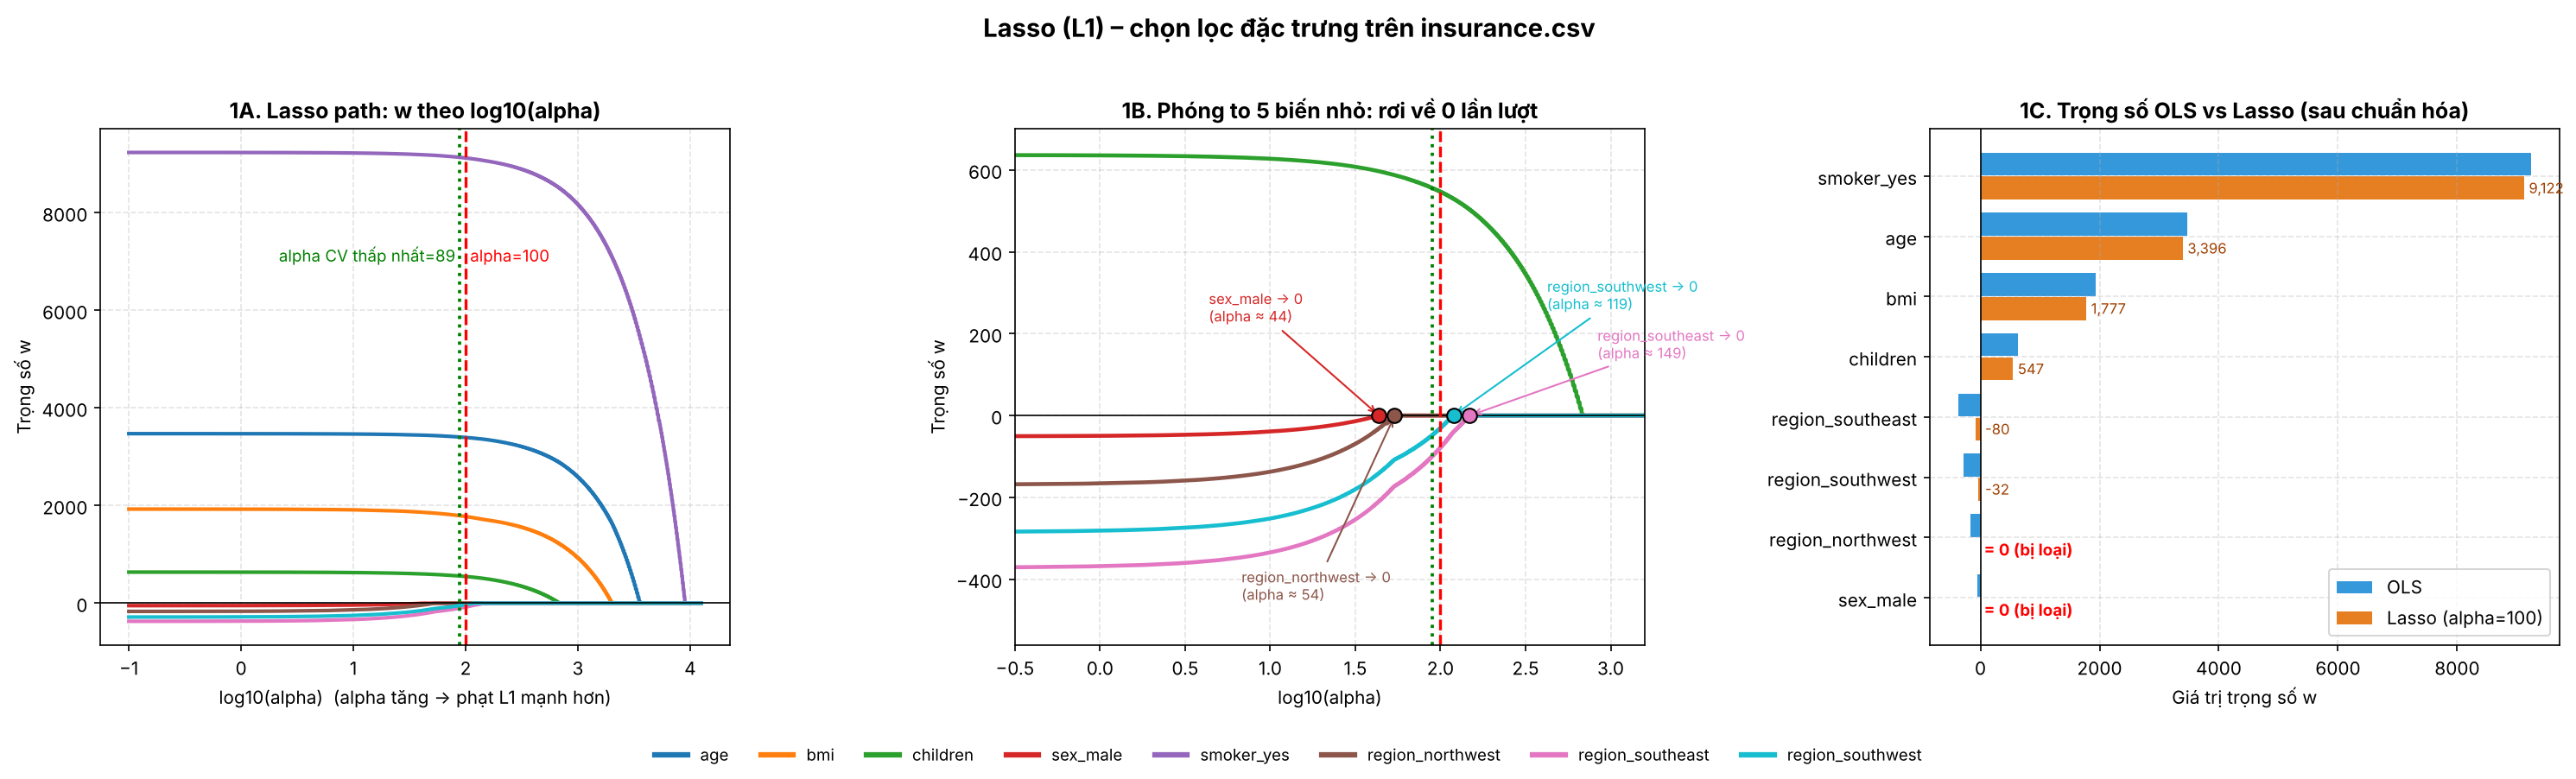

In [28]:
LA_ALPHA, LA_CV = np.log10(ALPHA), np.log10(cv_best_alpha)   # vị trí alpha demo và alpha CV trên trục log

# Hình 1
fig, ax = plt.subplots(1, 3, figsize=(20, 6), dpi=150)
for i, f in enumerate(feat):
    ax[0].plot(la, coefs_p[i], lw=2, color=COLORS[f], label=f)
ax[0].axhline(0, color="k", lw=0.8)
ax[0].axvline(LA_ALPHA, color="red", ls="--", lw=1.6)
ax[0].axvline(LA_CV, color="green", ls=":", lw=1.8)
ax[0].text(LA_ALPHA + 0.04, 7000, f"alpha={ALPHA:g}", color="red", fontsize=9)
ax[0].text(LA_CV - 0.04, 7000, f"alpha CV thấp nhất={cv_best_alpha:.0f}", color="green", fontsize=9, ha="right")
ax[0].set_title("1A. Lasso path: w theo log10(alpha)", fontweight="bold")
ax[0].set_xlabel("log10(alpha)  (alpha tăng -> phạt L1 mạnh hơn)")
ax[0].set_ylabel("Trọng số w")

small = ["children", "sex_male", "region_northwest", "region_southeast", "region_southwest"]
for f in small:
    ax[1].plot(la, coefs_p[feat.index(f)], lw=2.2, color=COLORS[f])
ax[1].axhline(0, color="k", lw=0.8)
ax[1].axvline(LA_ALPHA, color="red", ls="--", lw=1.6)
ax[1].axvline(LA_CV, color="green", ls=":", lw=1.8)
ax[1].set_ylim(-560, 700)
ax[1].set_xlim(-0.5, 3.2)
offs = {"sex_male": (-1.0, 230), "region_northwest": (-0.9, -450),
        "region_southwest": (0.55, 260), "region_southeast": (0.75, 140)}
for f, (dx, dy) in offs.items():
    t = np.log10(zero_at[f])
    ax[1].plot(t, 0, "o", color=COLORS[f], ms=8, mec="k", zorder=5)
    ax[1].annotate(f"{f} -> 0\n(alpha ≈ {zero_at[f]:.0f})", (t, 0), (t + dx, dy), fontsize=8,
                   color=COLORS[f], arrowprops=dict(arrowstyle="->", color=COLORS[f]))
ax[1].set_title("1B. Phóng to 5 biến nhỏ: rơi về 0 lần lượt", fontweight="bold")
ax[1].set_xlabel("log10(alpha)")
ax[1].set_ylabel("Trọng số w")

order = W["OLS"].abs().sort_values().index
yy = np.arange(len(order))
ax[2].barh(yy + 0.2, W.loc[order, "OLS"], 0.38, color="#3498db", label="OLS")
ax[2].barh(yy - 0.2, W.loc[order, "Lasso"], 0.38, color="#e67e22", label=f"Lasso (alpha={ALPHA:g})")
for k, f in enumerate(order):
    v = W.loc[f, "Lasso"]
    if abs(v) < 1e-4:
        ax[2].text(60, k - 0.2, "= 0 (bị loại)", color="red", va="center", fontsize=9, fontweight="bold")
    else:
        ax[2].text(max(v, 0) + 80, k - 0.2, f"{v:,.0f}", va="center", fontsize=8, color="#a04000")
ax[2].set_yticks(yy)
ax[2].set_yticklabels(order)
ax[2].axvline(0, color="k", lw=0.8)
ax[2].set_title("1C. Trọng số OLS vs Lasso (sau chuẩn hóa)", fontweight="bold")
ax[2].set_xlabel("Giá trị trọng số w")
ax[2].legend(loc="lower right")
h = [plt.Line2D([0], [0], color=COLORS[f], lw=3) for f in feat]
fig.legend(h, feat, loc="lower center", ncol=8, fontsize=9, frameon=False)
fig.suptitle("Lasso (L1) – chọn lọc đặc trưng trên insurance.csv", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0.06, 1, 0.96])
plt.savefig(PLOTS_DIR / "3_lasso_l1_feature_selection.png")
plt.show()

### 4.3.7 Hình 2: hình học hình thoi (L1) vs hình tròn (L2) 
Bài toán Lasso tương đương: *cực tiểu MSE với ràng buộc* $|w_1|+|w_2|\le t$.
- Các đường cong xanh là **đường đồng mức của MSE** (ellipse), tâm là nghiệm OLS (ngôi sao). Ellipse càng xa tâm thì sai số càng lớn.
- Nghiệm là điểm **đầu tiên ellipse chạm vùng ràng buộc** (đường đỏ đậm).
- Hình thoi có **đỉnh nằm trên trục**, ellipse thường chạm đúng đỉnh nên $w_2=0$. Hình tròn không có đỉnh nên $w_1,w_2\neq0$.
- Nhiều chiều thì hình thoi có rất nhiều đỉnh/cạnh trên các trục tọa độ, nên càng dễ có nhiều $w_j=0$.

*Lưu ý: đây là minh họa với 2 trọng số, không phải dữ liệu thật.*

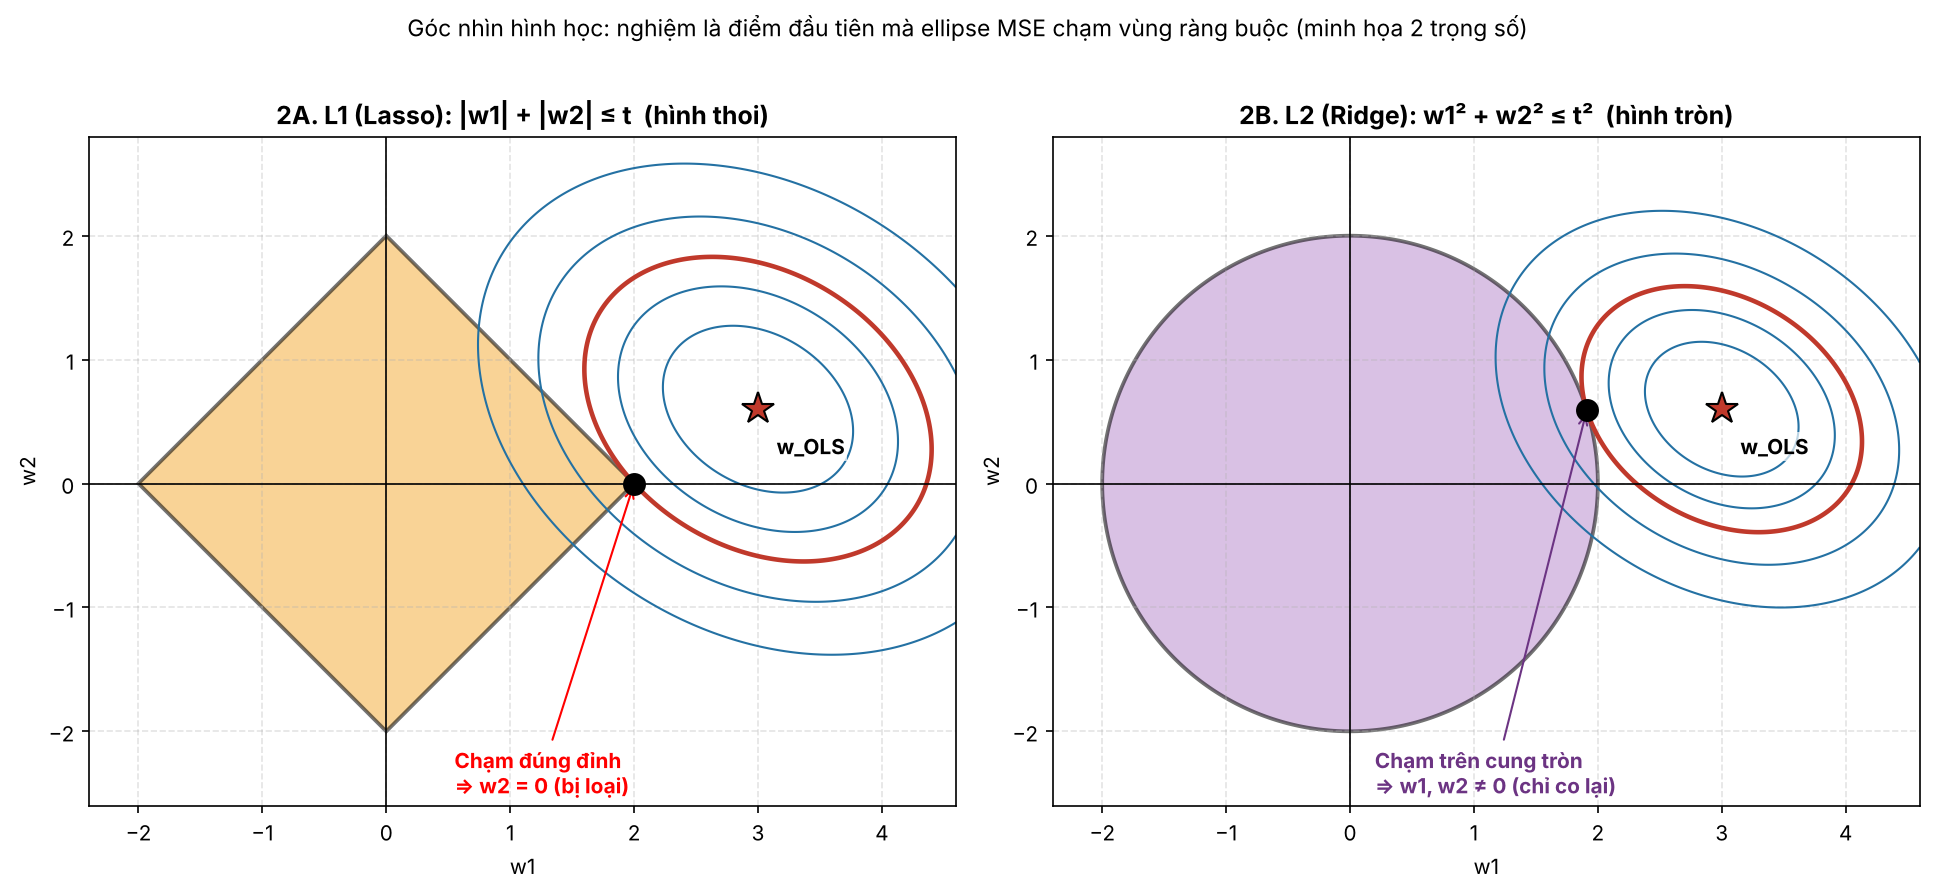

In [29]:
# Hình 2
SIG = np.array([[1.0, 0.3], [0.3, 1.3]])      # ma trận định dạng ellipse (minh họa)
W0 = np.array([3.0, 0.6])                      # nghiệm OLS (tâm ellipse)
T = 2.0                                        # bán kính ngân sách


def constrained_min(shape, k=20000):
    th = np.linspace(0, 2 * np.pi, k, endpoint=False)
    c, s = np.cos(th), np.sin(th)
    r = T / (np.abs(c) + np.abs(s)) if shape == "l1" else T * np.ones_like(th)
    P = np.c_[r * c, r * s]
    d = P - W0
    L = np.einsum("ij,jk,ik->i", d, SIG, d)
    i = L.argmin()
    return P[i], L[i]


gx, gy = np.meshgrid(np.linspace(-2.4, 4.6, 500), np.linspace(-2.6, 2.8, 500))
D = np.stack([gx - W0[0], gy - W0[1]], -1)
Z = np.einsum("...i,ij,...j->...", D, SIG, D)
th = np.linspace(0, 2 * np.pi, 400)
fig, ax = plt.subplots(1, 2, figsize=(13, 6), dpi=150)
for a, shape, col, ttl in [(ax[0], "l1", "#f5b041", "2A. L1 (Lasso): |w1| + |w2| ≤ t  (hình thoi)"),
                           (ax[1], "l2", "#bb8fce", "2B. L2 (Ridge): w1² + w2² ≤ t²  (hình tròn)")]:
    p, lmin = constrained_min(shape)
    if shape == "l1":
        a.fill([T, 0, -T, 0], [0, T, 0, -T], color=col, alpha=0.55, ec="k", lw=1.8)
    else:
        a.fill(T * np.cos(th), T * np.sin(th), color=col, alpha=0.55, ec="k", lw=1.8)
    a.contour(gx, gy, Z, levels=[lmin * 0.3, lmin * 0.65, lmin * 1.6, lmin * 2.6], colors="#2471a3", linewidths=1.0)
    a.contour(gx, gy, Z, levels=[lmin], colors="#c0392b", linewidths=2.2)
    a.plot(*W0, "*", color="#c0392b", ms=16, mec="k", zorder=6)
    a.text(W0[0] + 0.15, W0[1] - 0.2, "w_OLS", fontsize=10, fontweight="bold", va="top",
           bbox=dict(fc="white", ec="none", alpha=0.7, pad=1))
    a.plot(*p, "o", color="k", ms=10, zorder=7)
    if shape == "l1":
        a.annotate("Chạm đúng đỉnh\n=> w2 = 0 (bị loại)", p, (0.55, -2.5), fontsize=10,
                   color="red", fontweight="bold", arrowprops=dict(arrowstyle="->", color="red"))
    else:
        a.annotate("Chạm trên cung tròn\n=> w1, w2 ≠ 0 (chỉ co lại)", p, (0.2, -2.5), fontsize=10,
                   color="#6c3483", fontweight="bold", arrowprops=dict(arrowstyle="->", color="#6c3483"))
    a.axhline(0, color="k", lw=0.8)
    a.axvline(0, color="k", lw=0.8)
    a.set_aspect("equal")
    a.set_xlim(-2.4, 4.6)
    a.set_ylim(-2.6, 2.8)
    a.set_xlabel("w1")
    a.set_ylabel("w2")
    a.set_title(ttl, fontweight="bold")
fig.suptitle("Góc nhìn hình học: nghiệm là điểm đầu tiên mà ellipse MSE chạm vùng ràng buộc (minh họa 2 trọng số)",
             fontsize=11)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "3_lasso_geometry_l1_vs_l2.png")
plt.show()

### 4.3.8 Hình 3: đạo hàm của phạt và soft-thresholding 
**3A – đạo hàm:** phạt L1 có đạo hàm $\operatorname{sign}(w)$, lực kéo về 0 luôn bằng $\pm1$ (nhân $\alpha$) dù $w$ nhỏ đến đâu. Phạt L2 có đạo hàm $w$, tiến về 0 khi $w\to0$ nên cuối cùng hết lực, chỉ co lại chứ không chạm 0. Tại $w=0$ thì $|w|$ không khả vi, ta dùng *dưới đạo hàm* là mọi giá trị trong $[-1,1]$.

**3B – soft-thresholding:** đường cam là $S(w_{OLS},100)$, vùng vàng $|w_{OLS}|\le100$ là "vùng chết" cho $w=0$. Các chấm là kết quả thật của 5 biến nhỏ. `children` nằm sát đường lý thuyết, còn các biến `region` lệch khỏi đường vì chúng tương quan với nhau (xem 4.3.4).

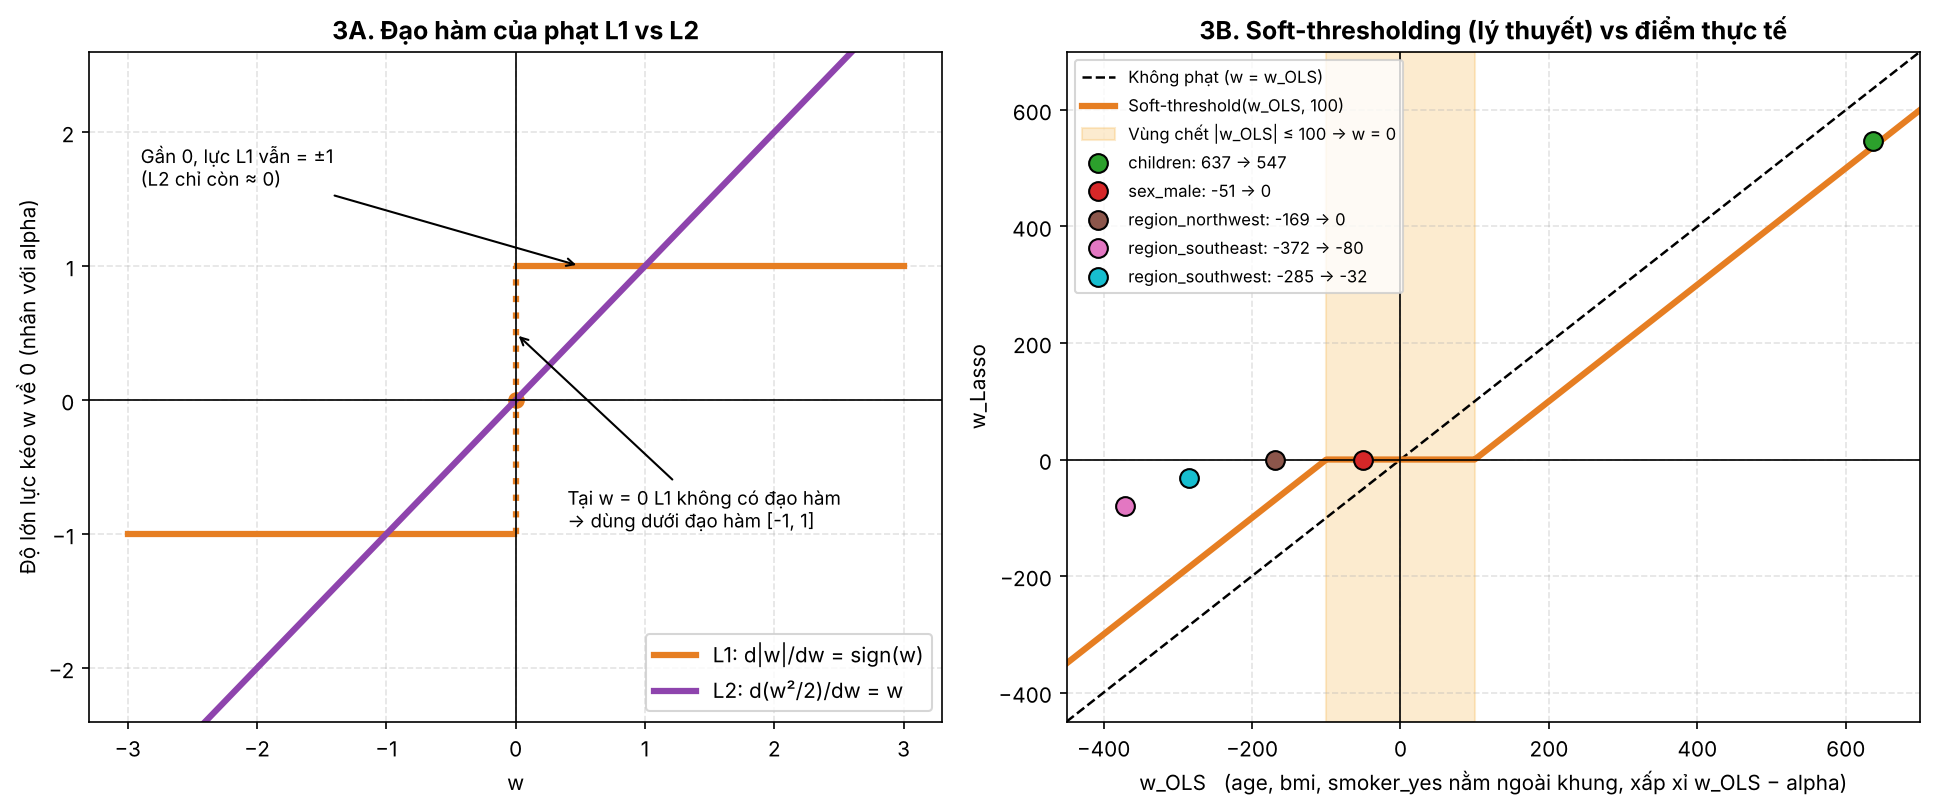

In [30]:
# Hình 3
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5), dpi=150)
w = np.linspace(-3, 3, 601)
wl, wr = w[w < 0], w[w > 0]
ax[0].plot(wl, -np.ones_like(wl), color="#e67e22", lw=3, label="L1: d|w|/dw = sign(w)")
ax[0].plot(wr, np.ones_like(wr), color="#e67e22", lw=3)
ax[0].plot([0, 0], [-1, 1], color="#e67e22", lw=3, ls=":")
ax[0].plot(0, 0, "o", color="#e67e22", ms=7)
ax[0].plot(w, w, color="#8e44ad", lw=3, label="L2: d(w²/2)/dw = w")
ax[0].annotate("Tại w = 0 L1 không có đạo hàm\n-> dùng dưới đạo hàm [-1, 1]", (0, 0.5), (0.4, -0.95),
               fontsize=9, arrowprops=dict(arrowstyle="->"))
ax[0].annotate("Gần 0, lực L1 vẫn = ±1\n(L2 chỉ còn ≈ 0)", (0.5, 1), (-2.9, 1.6), fontsize=9,
               arrowprops=dict(arrowstyle="->"))
ax[0].axhline(0, color="k", lw=0.8)
ax[0].axvline(0, color="k", lw=0.8)
ax[0].set_ylim(-2.4, 2.6)
ax[0].set_xlabel("w")
ax[0].set_ylabel("Độ lớn lực kéo w về 0 (nhân với alpha)")
ax[0].set_title("3A. Đạo hàm của phạt L1 vs L2", fontweight="bold")
ax[0].legend(loc="lower right")

xs = np.linspace(-450, 700, 800)
ax[1].plot(xs, xs, "k--", lw=1.2, label="Không phạt (w = w_OLS)")
ax[1].plot(xs, soft_threshold(xs, ALPHA), color="#e67e22", lw=3, label=f"Soft-threshold(w_OLS, {ALPHA:g})")
ax[1].axvspan(-ALPHA, ALPHA, color="#f5b041", alpha=0.25, label=f"Vùng chết |w_OLS| ≤ {ALPHA:g} -> w = 0")
for f in small:
    xo, yo = W.loc[f, "OLS"], W.loc[f, "Lasso"]
    ax[1].plot(xo, yo, "o", color=COLORS[f], ms=9, mec="k", zorder=5,
               label=f"{f}: {int(round(xo)):,} -> {int(round(yo)):,}")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].axvline(0, color="k", lw=0.8)
ax[1].set_xlim(-450, 700)
ax[1].set_ylim(-450, 700)
ax[1].set_xlabel("w_OLS   (age, bmi, smoker_yes nằm ngoài khung, xấp xỉ w_OLS − alpha)")
ax[1].set_ylabel("w_Lasso")
ax[1].set_title("3B. Soft-thresholding (lý thuyết) vs điểm thực tế", fontweight="bold")
ax[1].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "3_lasso_soft_threshold_derivative.png")
plt.show()

### 4.3.9 Hình 4: chọn alpha
- **4A:** RMSE của 5-fold CV (trên Train) theo alpha; dải mờ là sai số chuẩn giữa các fold. Điểm xanh là alpha có CV RMSE thấp nhất (≈89). Đường đỏ là alpha = 100: RMSE gần như trùng.
- **4B:** alpha tăng thì R² CV giảm dần (đường xanh) và số trọng số bằng 0 tăng theo bậc thang (đường đỏ). Đây là sự **đánh đổi giữa độ chính xác và độ gọn** của mô hình. Cả hai đường đều tính từ Train, không dùng Test.

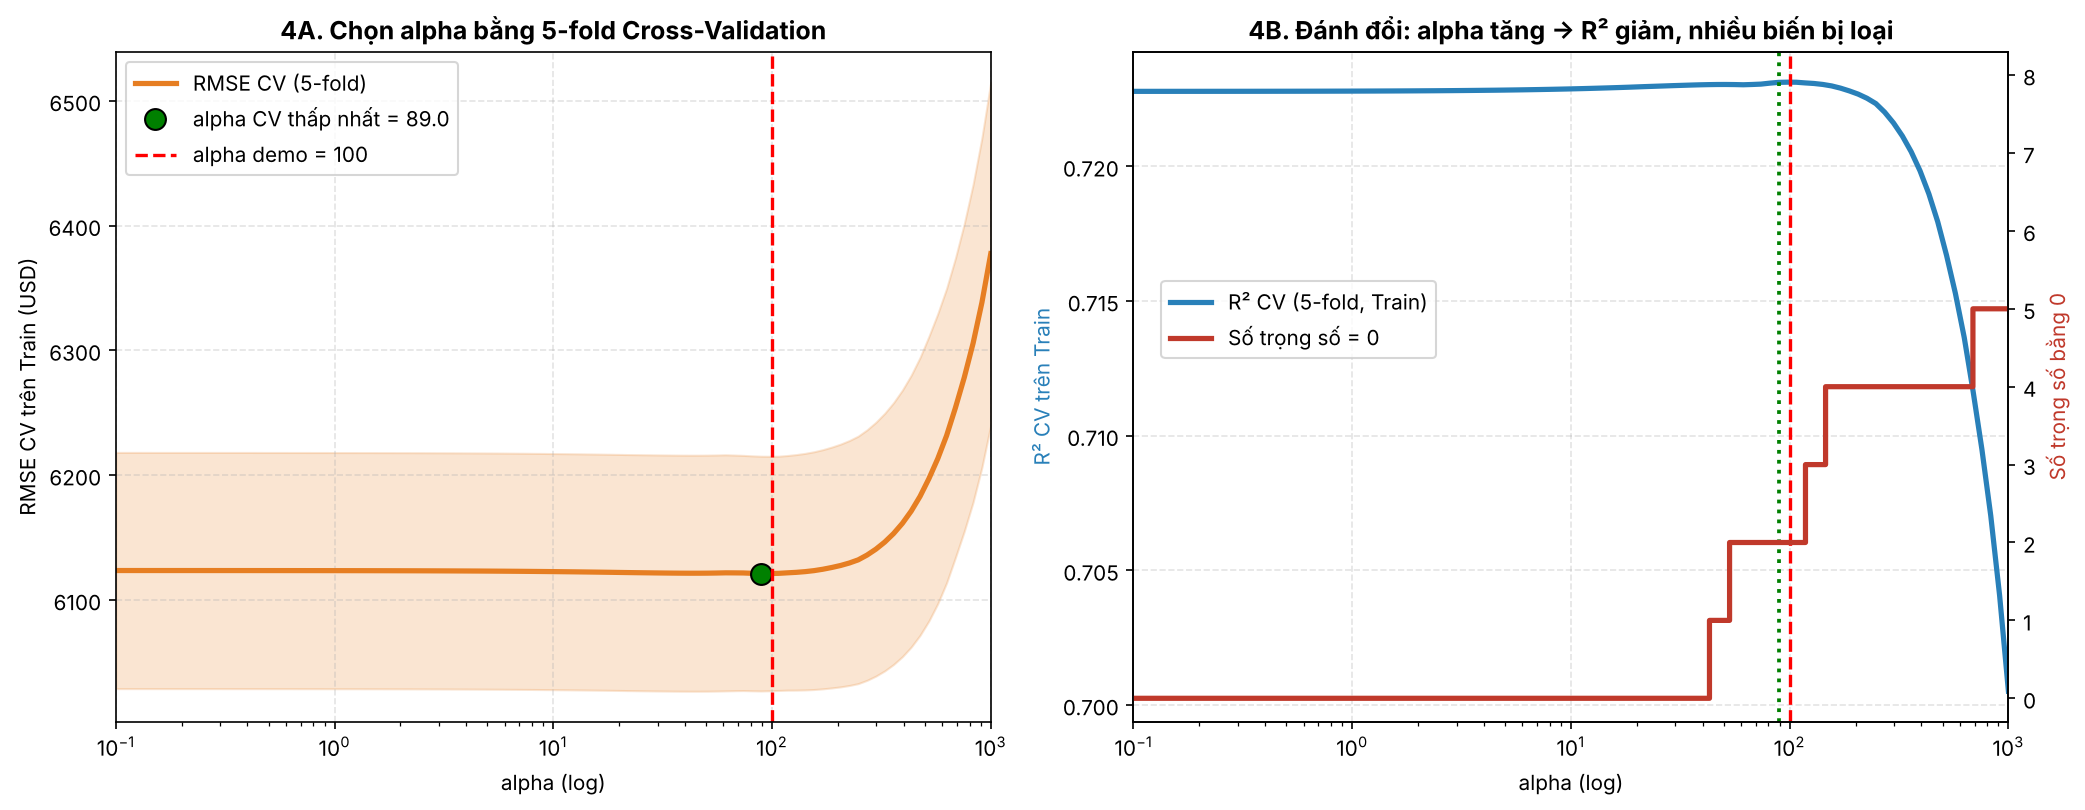

In [31]:
# Hình 4
rmse_cv = lasso_cv_tab["cv_rmse"].to_numpy()
se_cv = lasso_cv_tab["cv_rmse_sd"].to_numpy() / np.sqrt(CV_FOLDS)
n_zero = (np.abs(coefs_p) < 1e-8).sum(0)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150)
ax[0].plot(cv_alphas, rmse_cv, color="#e67e22", lw=2.5, label="RMSE CV (5-fold)")
ax[0].fill_between(cv_alphas, rmse_cv - se_cv, rmse_cv + se_cv, color="#e67e22", alpha=0.2)
ax[0].plot(cv_best_alpha, rmse_cv.min(), "o", color="green", ms=10, mec="k",
           label=f"alpha CV thấp nhất = {cv_best_alpha:.1f}")
ax[0].axvline(ALPHA, color="red", ls="--", lw=1.6, label=f"alpha demo = {ALPHA:g}")
ax[0].set_xscale("log")
ax[0].set_xlim(cv_alphas.min(), cv_alphas.max())
ax[0].set_xlabel("alpha (log)")
ax[0].set_ylabel("RMSE CV trên Train (USD)")
ax[0].set_title("4A. Chọn alpha bằng 5-fold Cross-Validation", fontweight="bold")
ax[0].legend()

ax[1].plot(cv_alphas, lasso_cv_tab["cv_r2"], color="#2980b9", lw=2.5, label="R² CV (5-fold, Train)")
ax[1].axvline(ALPHA, color="red", ls="--", lw=1.6)
ax[1].axvline(cv_best_alpha, color="green", ls=":", lw=1.8)
ax[1].set_xscale("log")
ax[1].set_xlim(cv_alphas.min(), cv_alphas.max())
ax[1].set_xlabel("alpha (log)")
ax[1].set_ylabel("R² CV trên Train", color="#2980b9")
a2 = ax[1].twinx()
a2.step(alphas_p, n_zero, where="post", color="#c0392b", lw=2.5, label="Số trọng số = 0")
a2.set_ylim(-0.3, 8.3)
a2.set_ylabel("Số trọng số bằng 0", color="#c0392b")
a2.grid(False)
ax[1].set_title("4B. Đánh đổi: alpha tăng -> R² giảm, nhiều biến bị loại", fontweight="bold")
l1_, n1_ = ax[1].get_legend_handles_labels()
l2_, n2_ = a2.get_legend_handles_labels()
ax[1].legend(l1_ + l2_, n1_ + n2_, loc="center left", bbox_to_anchor=(0.02, 0.6))
plt.tight_layout()
plt.savefig(PLOTS_DIR / "3_lasso_alpha_tuning.png")
plt.show()

## 4.4 ElasticNet (L1 + L2)

**Ý tưởng:** kết hợp phạt L1 (chọn biến) và L2 (ổn định nhóm biến tương quan). Hàm mục tiêu của sklearn đã ghi ở Phần 2. Đổi sang dạng slide ($\lambda_1,\lambda_2$, không chia $2n$) bằng cách nhân hai vế với $2n$:

$$\lambda_1=2n\,\alpha\rho,\qquad \lambda_2=n\,\alpha(1-\rho)$$

Với $n=1069$, $\alpha=100$, $\rho=0.9998$: $\lambda_1\approx 213{,}757$ và $\lambda_2\approx 21.4$. Phần L2 rất nhỏ nhưng **không vô nghĩa**: lực kéo của L2 tỉ lệ với $w$, nên với biến có $w$ cỡ 9,000 như `smoker_yes` nó vẫn co lại thấy rõ (xem 4.4.1).

### 4.4.1 Coordinate Descent cho ElasticNet và tác động của phần L2
Với $X$ đã chuẩn hóa ($x_j^\top x_j/n=1$), cập nhật từng biến là
$$w_j=\frac{S(\rho_j,\ \alpha\rho)}{1+\alpha(1-\rho)}$$
Mẫu số $1+\alpha(1-\rho)=1.02$ chia nhỏ *mọi* trọng số còn sống khoảng 2%. Đó là lý do ElasticNet co mạnh hơn Lasso ở `smoker_yes`, `age`, `bmi`. Ô dưới tự cài và so với sklearn.

In [32]:
def soft_thr(z, a):
    return np.sign(z) * np.maximum(np.abs(z) - a, 0.0)

def elasticnet_cd(Xs, ys, alpha, l1_ratio, n_iter=20000, tol=1e-10):
    # min (1/2n)||y - Xw||^2 + alpha*l1_ratio*||w||_1 + alpha*(1-l1_ratio)/2*||w||_2^2
    m, p = Xs.shape
    w = np.zeros(p)
    r = ys - ys.mean()
    for _ in range(n_iter):
        w_old = w.copy()
        for j in range(p):
            r += Xs[:, j] * w[j]
            rho_j = Xs[:, j] @ r / m
            w[j] = soft_thr(rho_j, alpha * l1_ratio) / (Xs[:, j] @ Xs[:, j] / m + alpha * (1 - l1_ratio))
            r -= Xs[:, j] * w[j]
        if np.max(np.abs(w - w_old)) < tol:
            break
    return w

w_en_cd = elasticnet_cd(X_tr, y_tr, ALPHA_EN, L1_RATIO_EN)
enet_tight = ElasticNet(alpha=ALPHA_EN, l1_ratio=L1_RATIO_EN, tol=1e-12, max_iter=500000).fit(X_tr, y_train)
cmp_en = pd.DataFrame({"Tự cài (CD)": w_en_cd, "sklearn": enet_tight.coef_, "Lasso": las.coef_}, index=feat)
alive = np.abs(las.coef_) > ZERO_TOL
cmp_en["ElasticNet / Lasso"] = np.where(alive, enet_tight.coef_ / np.where(alive, las.coef_, 1.0), np.nan)
display(cmp_en.round(4))
print(f"Sai lệch lớn nhất giữa bản tự cài và sklearn: {np.max(np.abs(w_en_cd - enet_tight.coef_)):.2e} USD")
print(f"1/(1+alpha*(1-rho)) = {1 / (1 + ALPHA_EN * (1 - L1_RATIO_EN)):.4f}")

,Tự cài (CD),sklearn,Lasso,ElasticNet / Lasso
age,"3,327.08","3,327.08","3,395.69",0.98
bmi,"1,740.39","1,740.39","1,776.97",0.98
children,544.33,544.33,547.36,0.99
sex_male,-0.00,-0.00,-0.00,NaN
smoker_yes,"8,938.00","8,938.00","9,121.86",0.98
region_northwest,-0.00,-0.00,-0.00,NaN
region_southeast,-55.58,-55.58,-80.01,0.69
region_southwest,-29.07,-29.07,-31.81,0.91


Sai lệch lớn nhất giữa bản tự cài và sklearn: 3.82e-10 USD
1/(1+alpha*(1-rho)) = 0.9804


### 4.4.2 Ảnh hưởng của `l1_ratio` ($\rho$) khi giữ $\alpha=100$
$\rho=1$ là Lasso thuần. $\rho$ giảm thì phần L1 yếu đi ($\alpha\rho$ nhỏ lại) và phần L2 $\frac{\alpha(1-\rho)}{2}\lVert w\rVert^2$ mạnh lên. Mỗi `l1_ratio` được đánh giá bằng 5-fold CV trên Train (không dùng Test); số trọng số bằng 0 lấy từ mô hình fit trên Train.

,Zero_Weights,CV RMSE,CV R2,Biến bị loại
l1_ratio,,,,
0.050000,0,"11,600.20",0.0126,-
0.100000,0,"11,595.43",0.0135,-
0.250000,0,"11,577.35",0.0165,-
0.500000,0,"11,523.68",0.0256,-
0.750000,0,"11,367.52",0.0519,-
0.900000,0,"10,938.93",0.1221,-
0.990000,0,"7,960.69",0.5350,-
0.999800,2,"6,128.94",0.7226,"sex_male, region_northwest"
1.000000,2,"6,121.25",0.7231,"sex_male, region_northwest"


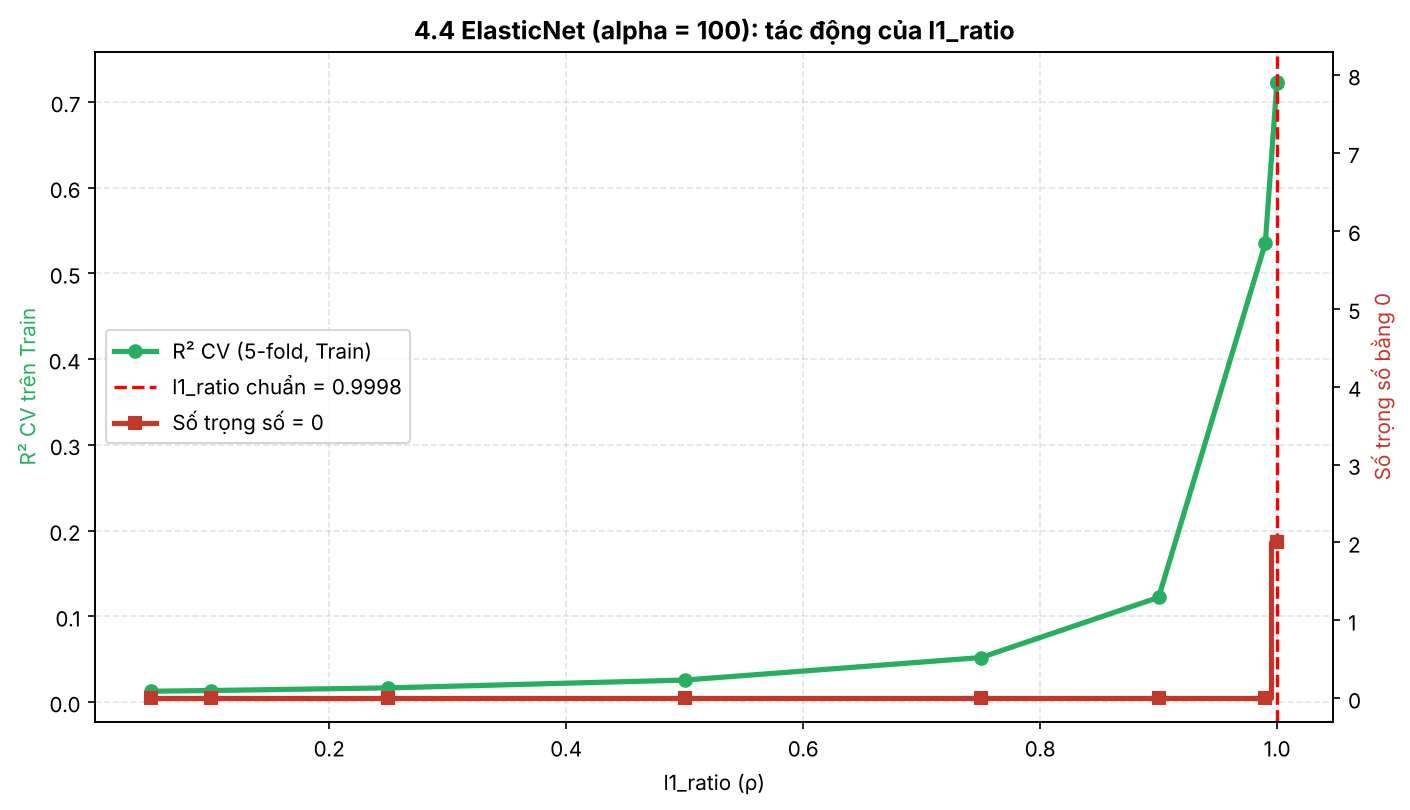

In [33]:
rhos = [0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99, 0.9998, 1.0]
rows_r = []
for rho in rhos:
    en_rho = ElasticNet(alpha=ALPHA_EN, l1_ratio=rho, max_iter=MAX_ITER)
    r = cv_scores(en_rho)
    fitted = clone(en_rho).fit(X_tr, y_train)
    rows_r.append({"l1_ratio": rho, "Zero_Weights": int((np.abs(fitted.coef_) < ZERO_TOL).sum()),
                   "CV RMSE": -r["test_rmse"].mean(), "CV R2": r["test_r2"].mean(),
                   "Biến bị loại": ", ".join(f for f, c in zip(feat, fitted.coef_) if abs(c) < ZERO_TOL) or "-"})
rho_tab = pd.DataFrame(rows_r).set_index("l1_ratio")
rho_tab.to_csv(OUT_DIR / "elasticnet_l1_ratio_cv.csv")
display(rho_tab.style.format({"CV RMSE": "{:,.2f}", "CV R2": "{:.4f}"}))

fig, ax = plt.subplots(figsize=(9.5, 5.5), dpi=150)
ax.plot(rho_tab.index, rho_tab["CV R2"], "o-", color="#27ae60", lw=2.5, label="R² CV (5-fold, Train)")
ax.axvline(L1_RATIO_EN, color="red", ls="--", lw=1.6, label=f"l1_ratio chuẩn = {L1_RATIO_EN}")
ax.set_xlabel("l1_ratio (ρ)")
ax.set_ylabel("R² CV trên Train", color="#27ae60")
a2 = ax.twinx()
a2.step(rho_tab.index, rho_tab["Zero_Weights"], where="mid", color="#c0392b", lw=2.5, marker="s", label="Số trọng số = 0")
a2.set_ylabel("Số trọng số bằng 0", color="#c0392b")
a2.set_ylim(-0.3, 8.3)
a2.grid(False)
ax.set_title("4.4 ElasticNet (alpha = 100): tác động của l1_ratio", fontweight="bold")
h1, l1_ = ax.get_legend_handles_labels()
h2, l2_ = a2.get_legend_handles_labels()
ax.legend(h1 + h2, l1_ + l2_, loc="center left")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "4.4_elasticnet_l1_ratio.png")
plt.show()

**Đọc kết quả**
- Với $\alpha=100$ cố định, chỉ cần hạ $\rho$ xuống 0.99 là R² CV tụt từ khoảng 0.72 xuống khoảng 0.54, và còn khoảng 0.01 ở $\rho=0.05$. Phần L2 $\alpha(1-\rho)/2$ đủ lớn để ép mọi trọng số về gần 0 (underfit nặng), dù không biến nào về đúng 0.
- Lasso và ElasticNet chia MSE cho $2n$ nên $\alpha=100$ đã là mức phạt rất mạnh. Chỉ khi $\rho$ sát 1 thì phần L2 mới đủ nhỏ để R² CV còn ≈ 0.72.
- Hệ quả khi bảo vệ: **ElasticNet với $\rho=0.9998$ gần như Lasso (L2 gần tắt), không phải cấu hình cân bằng L1/L2.** $\alpha=100$, $\rho=0.9998$ là cấu hình nhóm chọn để minh họa, không phải cấu hình ElasticNet tối ưu. Bảng này cho thấy kết quả rất nhạy với $\rho$ ở $\alpha$ lớn.

### 4.4.3 Coefficient Path: ElasticNet $\rho=0.9998$ so với $\rho=0.5$
Hai panel cùng trục alpha. $\rho=0.9998$ gần như Lasso (các đường chạm 0 rồi nằm yên). $\rho=0.5$ có phần L2 mạnh hơn nên đường cong mượt hơn.

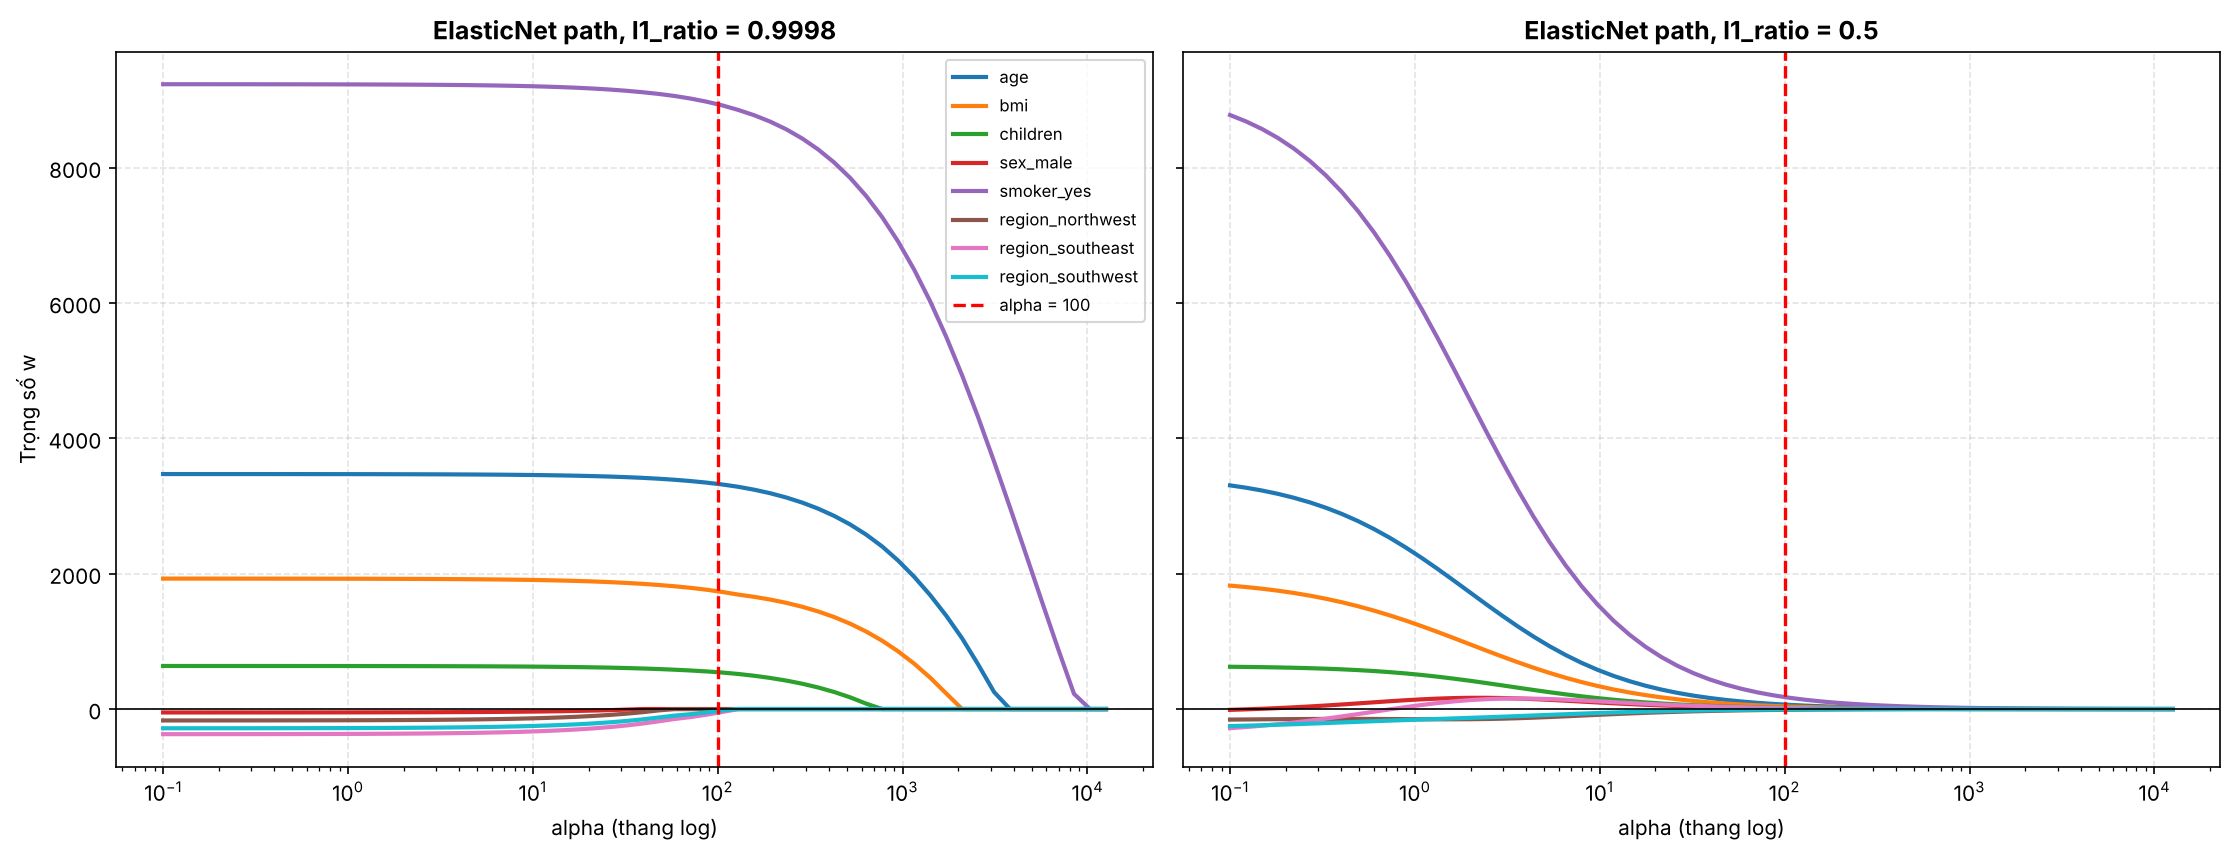

In [34]:
en_alphas = np.logspace(-1, 4.1, 60)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.8), dpi=150, sharey=True)
for a, rho in zip(ax, [L1_RATIO_EN, 0.5]):
    path_c = np.array([ElasticNet(alpha=al, l1_ratio=rho, max_iter=50000, tol=1e-8).fit(X_tr, y_train).coef_ for al in en_alphas])
    for i, f in enumerate(feat):
        a.plot(en_alphas, path_c[:, i], lw=2, color=COLORS[f], label=f)
    a.set_xscale("log")
    a.axhline(0, color="k", lw=0.8)
    a.axvline(ALPHA_EN, color="red", ls="--", lw=1.6, label=f"alpha = {ALPHA_EN:g}")
    a.set_xlabel("alpha (thang log)")
    a.set_title(f"ElasticNet path, l1_ratio = {rho}", fontweight="bold")
ax[0].set_ylabel("Trọng số w")
ax[0].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "4.4_elasticnet_path.png")
plt.show()

### 4.4.4 Tính ổn định với nhóm biến tương quan (mô phỏng)
Trong `insurance.csv` các biến chỉ tương quan nhẹ (xem VIF ở 4.2.1) nên không thấy rõ lợi thế này. Để minh họa lý thuyết, ô dưới dùng **dữ liệu mô phỏng** (không phải insurance): hai biến $x_1,x_2$ gần như trùng nhau (cùng $z$ cộng nhiễu nhỏ), $y=x_1+x_2+\text{nhiễu}$, lặp 100 lần với seed khác nhau. Mỗi chấm là $(w_1,w_2)$ của một lần chạy.

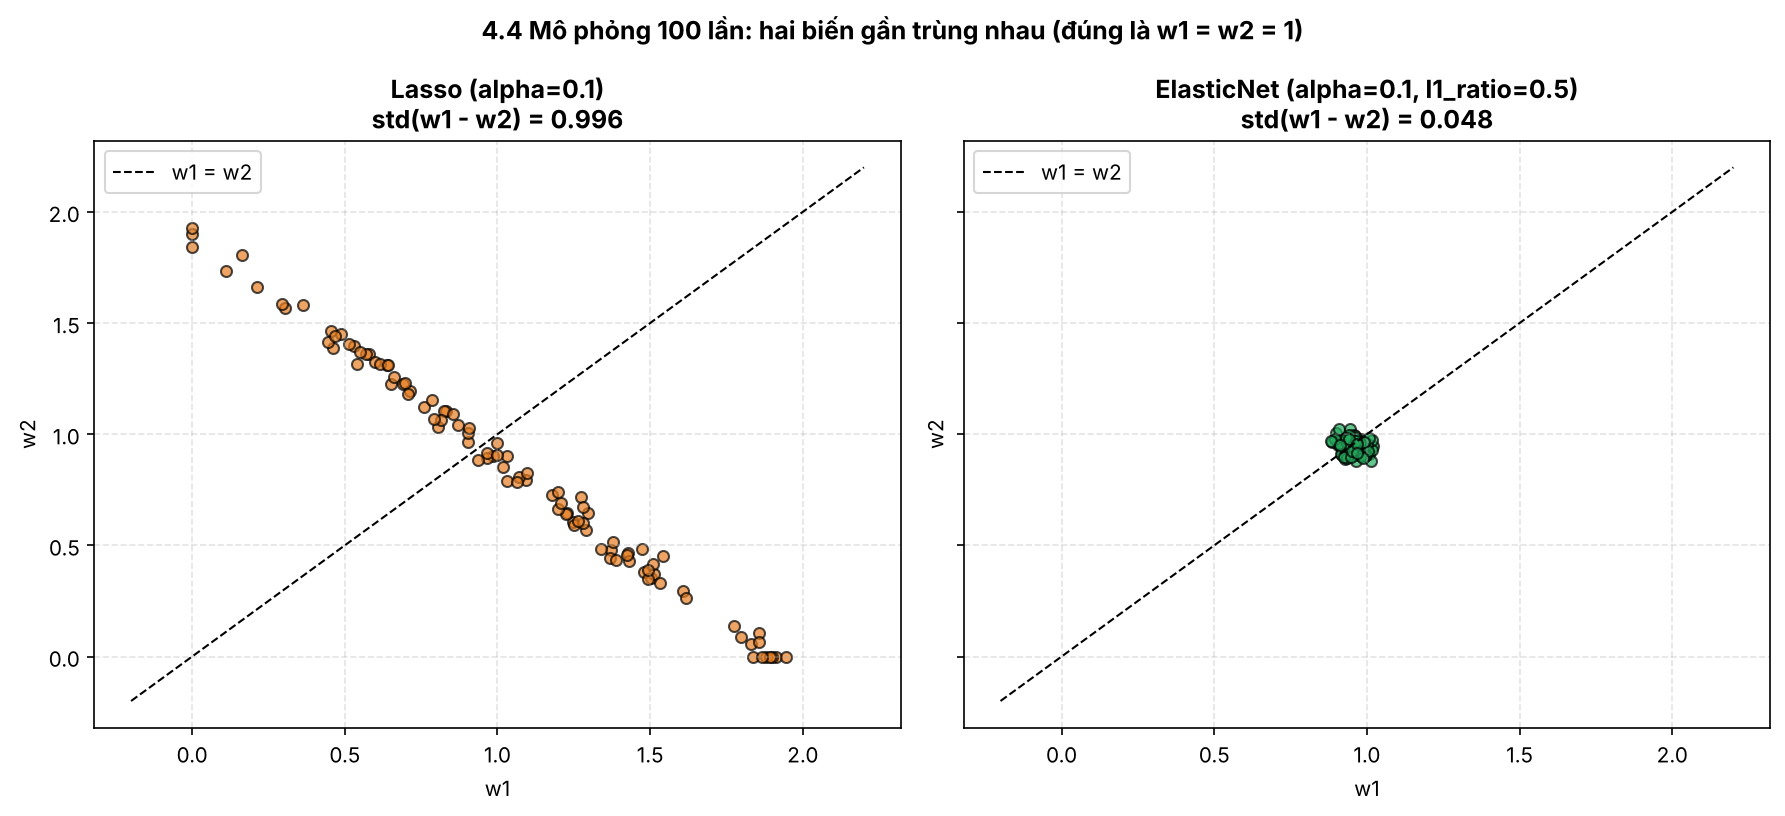

Lasso:      trung bình (w1, w2) = (1.046, 0.849) | std(w1 - w2) = 0.996
ElasticNet: trung bình (w1, w2) = (0.953, 0.945) | std(w1 - w2) = 0.048


In [35]:
def simulate(seed, n_syn=200):
    rng = np.random.default_rng(seed)
    z = rng.normal(size=n_syn)
    x1 = z + 0.05 * rng.normal(size=n_syn)
    x2 = z + 0.05 * rng.normal(size=n_syn)
    noise_vars = rng.normal(size=(n_syn, 3))
    Xs = np.c_[x1, x2, noise_vars]
    ys = x1 + x2 + 0.5 * rng.normal(size=n_syn)
    return Xs, ys

res_l, res_e = [], []
for s in range(100):
    Xs, ys = simulate(s)
    res_l.append(Lasso(alpha=0.1, max_iter=100000).fit(Xs, ys).coef_[:2])
    res_e.append(ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=100000).fit(Xs, ys).coef_[:2])
res_l, res_e = np.array(res_l), np.array(res_e)

fig, ax = plt.subplots(1, 2, figsize=(12, 5.5), dpi=150, sharex=True, sharey=True)
for a, rr, nm, col in [(ax[0], res_l, "Lasso (alpha=0.1)", MODEL_COLORS["Lasso"]),
                       (ax[1], res_e, "ElasticNet (alpha=0.1, l1_ratio=0.5)", MODEL_COLORS["ElasticNet"])]:
    a.scatter(rr[:, 0], rr[:, 1], s=28, alpha=0.7, color=col, edgecolor="k")
    a.plot([-0.2, 2.2], [-0.2, 2.2], "k--", lw=1, label="w1 = w2")
    a.set_xlabel("w1")
    a.set_ylabel("w2")
    a.set_title(f"{nm}\nstd(w1 - w2) = {np.std(rr[:, 0] - rr[:, 1]):.3f}", fontweight="bold")
    a.legend()
fig.suptitle("4.4 Mô phỏng 100 lần: hai biến gần trùng nhau (đúng là w1 = w2 = 1)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "4.4_elasticnet_group_stability.png")
plt.show()
print(f"Lasso:      trung bình (w1, w2) = ({res_l[:, 0].mean():.3f}, {res_l[:, 1].mean():.3f}) | std(w1 - w2) = {np.std(res_l[:, 0] - res_l[:, 1]):.3f}")
print(f"ElasticNet: trung bình (w1, w2) = ({res_e[:, 0].mean():.3f}, {res_e[:, 1].mean():.3f}) | std(w1 - w2) = {np.std(res_e[:, 0] - res_e[:, 1]):.3f}")

---
# Phần 5. Tổng kết

### 5.1 Bảng tổng kết (sinh tự động từ kết quả ở Phần 2 và mục 2.5)
Các cột không ghi CV là trên Test; các cột CV là 5-fold trên Train.

In [36]:
summary = results_num.loc[MODEL_ORDER, ["RMSE", "MAE", "R2", "Zero_Weights"]].copy()
summary["Δ R² so với OLS"] = summary["R2"] - summary.loc["OLS", "R2"]
summary["Δ RMSE so với OLS ($)"] = summary["RMSE"] - summary.loc["OLS", "RMSE"]
summary["CV RMSE ($)"] = cv_table.loc[MODEL_ORDER, "CV RMSE"]
summary["CV R²"] = cv_table.loc[MODEL_ORDER, "CV R2"]
display(summary.style.format({"RMSE": "{:,.2f}", "MAE": "{:,.2f}", "R2": "{:.4f}", "Δ R² so với OLS": "{:+.4f}",
                              "Δ RMSE so với OLS ($)": "{:+,.2f}", "CV RMSE ($)": "{:,.2f}", "CV R²": "{:.4f}"}))

,RMSE,MAE,R2,Zero_Weights,Δ R² so với OLS,Δ RMSE so với OLS ($),CV RMSE ($),CV R²
Model,,,,,,,,
OLS,"5,956.34","4,177.05",0.8069,0,+0.0000,+0.00,"6,123.65",0.7228
Ridge,"5,985.73","4,202.58",0.8050,0,-0.0019,+29.39,"6,124.56",0.7228
Lasso,"6,026.54","4,202.30",0.8024,2,-0.0046,+70.20,"6,121.25",0.7231
ElasticNet,"6,093.51","4,261.29",0.7979,2,-0.0090,+137.17,"6,128.94",0.7226


### 5.2 Kết luận

1. Cả 4 mô hình có R² test từ 0.798 đến 0.807 và RMSE test chênh nhau dưới 140 USD. OLS có sai số test thấp nhất, nhưng trên CV 5-fold chênh giữa các mô hình chỉ khoảng 8 USD, nhỏ hơn rất nhiều so với SD giữa các fold (≈210 USD). Vì vậy **không có mô hình nào chính xác hơn rõ rệt** trên dữ liệu này.
2. Lasso và ElasticNet cùng đưa `sex_male` và `region_northwest` về đúng 0 mà chỉ mất khoảng 0.005 đến 0.009 R² test. Giá trị của chúng ở đây là **mô hình gọn và dễ giải thích**. ElasticNet với $\rho=0.9998$ gần như Lasso.
3. Ridge không triệt tiêu biến nào, chỉ co hệ số rất nhẹ vì VIF thấp (đa cộng tuyến nhẹ) và $\alpha=10$ nhỏ so với $n=1069$.
4. `smoker_yes`, `age`, `bmi` là ba biến có trọng số chuẩn hóa lớn nhất ở cả 4 mô hình. Đây là mối liên hệ thống kê trong dữ liệu, **không phải quan hệ nhân quả**.
5. Giới hạn: kết quả test dựa trên một lần chia và cao hơn R² CV (0.807 so với 0.723); phần dư lệch phải và có phương sai không đều (mục 4.1.2); mô hình tuyến tính cộng gộp không bắt được tương tác giữa các biến.